# Go-to-Market Analysis for URJA EV: Launching an Electric Two-Wheeler in Mumbai
**Capstone Project 1 – Dashboarding**

URJA EV is a hypothetical new brand. This notebook cleans three datasets, does the EDA (exploratory data analysis), finds customer segments with K-Means, builds a launch scorecard, and saves the files for the Tableau dashboard.

| Dataset | Source | Type |
|---|---|---|
| Vehicle registrations (2020 to Oct 2026) | Vahan Dashboard, MoRTH | Real data (raw) |
| Public charging stations | Kaggle (saketpradhan) | Real data (raw) |
| Customer survey | Made up for this assignment | **Synthetic** data (raw) |

**Note:** the survey is synthetic, so survey insights are for practice and do not describe all Mumbai residents.

# Part A: Loading and Understanding the Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

warnings.filterwarnings("ignore")

In [2]:
reg = pd.read_csv(r"C:\Users\Shraddha\Downloads\registrations_raw (1).csv")
chg = pd.read_csv(r"C:\Users\Shraddha\Downloads\charging_stations_raw (1).csv")
sv = pd.read_csv(r"C:\Users\Shraddha\Downloads\CP_Project_Raw\survey_mumbai_2w_raw_synthetic.csv")

In [3]:
reg

,RTO Area,Year,Brand,Brand Type,Electric (BOV),Pure EV,EV Total
0,Mumbai West (MH02),2024,Chetak Technology Ltd,Legacy OEM,185,44.0,229
1,Mumbai (West),2023,Revolt,EV start-up,31,0.0,31
2,MH02,2023,Eicher Motors (Bus),NaN,37,0.0,37
3,mumbai east,2021.0,TVS (iQube),Legacy OEM,1,0.0,1
4,MUMBAI CENTRAL (MH01),2022,Other 2W EV makers,EV start-up,59,0.0,59
...,...,...,...,...,...,...,...
351,Mumbai East (MH03),2022,BGauss,EV start-up,14,0.0,14
352,Mumbai West (MH02),2023,Komaki,EV start-up,14,0.0,14
353,Mumbai Central (MH01),2024,Chetak Technology Ltd,Legacy OEM,64,32.0,96
354,Mumbai East (MH03),2022,Bajaj (Chetak),Legacy OEM,60,NaN,60


In [4]:
chg

,name,state,city,address,lattitude,longitude,type
0,Tata Power,Maharashtra,Mumbai,"CR - Lokmanya Tilak Station, Kurla, Outside Pl...",19.068262,72.890964,7.0
1,NaN,West Bengal,mumbai,"Runwal Anthurium Rd, opposite Veena Nagar, Var...",19.1806661685396,72.946847,6.0
2,ANERT-EESL ERNAKULAM KERALA,Kerala,Kochi,"Shanmugham Road, Ernakulam, Marine Drive, Koch...",9.977005426,76.277803,8.0
3,"Shree Shyam Motors, VKI Area",Rajasthan,Jaipur,"E(5) B, Road no 1C, VKI area, Jaipur - 302013",26.972289,75.777332,7.0
4,EESL Koyambedu,Tamil Nadu,Chennai,"Koyambedu, Chennai, Tamil Nadu 600107",13.07376771,80.194931,8.0
...,...,...,...,...,...,...,...
209,Tata Power,Maharashtra,Navi Mumbai,"Fortune Cars, Navi Mumbai, Plot No. D-400, TTC...",19.03639,73.029907,7.0
210,IDC Kitchen,Gujarat,bengaluru,"No 67, 80 Feet Road, KGEHBS Layout, Devasandra...",13.028052,77.572997,6.0
211,"EESL Adhoc New Central , HPCL, New town",West Bengal,Kolkata,"Akhankha ho petrol pump, Newtown, Kolkata, Wes...",22.61822126,88.466509,8.0
212,"Sairam Automobiles, Krishna Nagar",Chattisgarh,Bhilai,"Sairam auto G. E Road, Krishna Nagar, Supela, ...",21.2165392,81.401487,7.0


In [5]:
sv

,Respondent_ID,Timestamp,Age,Gender,Area,City,Profession,Personal_Monthly_Income_INR,Household_Monthly_Income_INR,Current_Vehicle,Daily_Commute_km,Budget_INR,EV_Interest,Main_Concern,Home_Charging_Possible,Range_Needed,Charging_Preference,Purchase_Influence_Channel,Data_Origin
0,MUM0123,13/10/2026 08:58:00,23,Man,Bandra West,Mumbai,Homemaker,0,10000,Petrol scooter,17.4,40000,Yes,Upfront price,No (shared/street parking),80-100 km,Prefer home charging only,Friends & family,Synthetic - Generated
1,MUM0032,2026-09-02 14:30,40,F,Andheri,Mumbai,Salaried (govt),44000,-,Bike (petrol),24.3,100000,YES,Charging availability,Yes (own/society parking),100-150 km,Prefer home charging only,YouTube / social media,Synthetic - Generated
2,MUM0326,20/10/2026 16:04:00,30,Female,Sion,Mumbai,IT / Tech,98000,159000,Car,16.1,135000,May be,Charging availability,No (shared/street parking),100-150 km,Fine with paid public charging,Online / brand website,Synthetic - Generated
3,MUM0320,17/10/2026 21:44:00,30,Man,Andheri,MUMBAI,Business / Self-employed,79000,93000,car,15.8,100000,Not sure,Resale value,Yes (own/society parking),100-150 km,Prefer home charging only,Dealer test-ride event,Synthetic - Generated
4,MUM0288,2026-10-08 06:14,38,F,Goregaon,Mumbai,Salaried (govt),38000,40k,Petrol scooter,5.5,95000,Yes,Range anxiety,No (shared/street parking),80-100 km,Prefer battery swapping,Friends & family,Synthetic - Generated
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
430,MUM0419,10/09/2026 08:42:00,46,Man,Kandivali,Mumbai,Business / Self-employed,238000,313000,motorcycle,18.4,3.05 lakh,Maybe,Range anxiety,No (shared/street parking),100-150 km,Prefer home charging only,Showroom visit,Synthetic - Generated
431,MUM0147,04/10/2026 03:11:00,31,female,Dadar,Mumbai,Homemaker,25000,54000,Electric 2W (already),18.6,55000,Yes,Upfront price,Yes (own/society parking),80-100 km,Fine with paid public charging,Showroom visit,Synthetic - Generated
432,MUM0102,27/09/2026 19:26:00,22,M,Sion,Navi Mumbai,-,10000,52000,public transport,7.2,40000,Maybe,After-sales service,No (shared/street parking),80-100 km,Fine with paid public charging,YouTube / social media,Synthetic - Generated
433,MUM0164,05/09/2026 00:26:00,34,M,Bandra West,Mumbai,IT / Tech,100000,131000,Petrol scooter,11.0,260000,yes,Battery life / replacement cost,No (shared/street parking),80-100 km,Prefer battery swapping,Showroom visit,Synthetic - Generated


In [6]:
print("Registrations :", reg.shape)
print("Charging      :", chg.shape)
print("Survey        :", sv.shape)

Registrations : (356, 7)
Charging      : (214, 7)
Survey        : (435, 19)


### Registrations data: first look

In [7]:
reg.head()

,RTO Area,Year,Brand,Brand Type,Electric (BOV),Pure EV,EV Total
0,Mumbai West (MH02),2024,Chetak Technology Ltd,Legacy OEM,185,44.0,229
1,Mumbai (West),2023,Revolt,EV start-up,31,0.0,31
2,MH02,2023,Eicher Motors (Bus),NaN,37,0.0,37
3,mumbai east,2021.0,TVS (iQube),Legacy OEM,1,0.0,1
4,MUMBAI CENTRAL (MH01),2022,Other 2W EV makers,EV start-up,59,0.0,59


In [8]:
reg.shape

(356, 7)

In [9]:
reg.info()

<class 'pandas.DataFrame'>
RangeIndex: 356 entries, 0 to 355
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   RTO Area        356 non-null    str    
 1   Year            356 non-null    str    
 2   Brand           356 non-null    str    
 3   Brand Type      323 non-null    str    
 4   Electric (BOV)  356 non-null    int64  
 5   Pure EV         350 non-null    float64
 6   EV Total        351 non-null    str    
dtypes: float64(1), int64(1), str(5)
memory usage: 35.3 KB


In [10]:
reg.isnull().sum()

RTO Area           0
Year               0
Brand              0
Brand Type        33
Electric (BOV)     0
Pure EV            6
EV Total           5
dtype: int64

In [11]:
reg.duplicated().sum()

np.int64(10)

In [12]:
reg['RTO Area'].value_counts()

RTO Area
Mumbai West (MH02)       76
Mumbai Central (MH01)    69
Mumbai East (MH03)       67
MH02                     15
mumbai east              14
MH01                     13
MUMBAI EAST (MH03)       13
mumbai central           12
Mumbai (West)            11
Mumbai Central           11
Mumbai West              10
MUMBAI CENTRAL (MH01)     9
MH03                      9
MUMBAI WEST (MH02)        7
Mumbai East               7
Mumbai-East               5
Mumbai Central(MH01)      4
mumbai west               4
Name: count, dtype: int64

In [13]:
reg['Brand'].nunique()

59

**Observation:** The registrations data has 356 rows and 7 columns. The same RTO area and the same brand are written in many ways, `Year` is text, some values are missing, there are 10 duplicate rows, and cars/buses/3-wheelers are mixed in with the two-wheelers.

### Charging stations data: first look

In [14]:
chg.head()

,name,state,city,address,lattitude,longitude,type
0,Tata Power,Maharashtra,Mumbai,"CR - Lokmanya Tilak Station, Kurla, Outside Pl...",19.068262,72.890964,7.0
1,NaN,West Bengal,mumbai,"Runwal Anthurium Rd, opposite Veena Nagar, Var...",19.1806661685396,72.946847,6.0
2,ANERT-EESL ERNAKULAM KERALA,Kerala,Kochi,"Shanmugham Road, Ernakulam, Marine Drive, Koch...",9.977005426,76.277803,8.0
3,"Shree Shyam Motors, VKI Area",Rajasthan,Jaipur,"E(5) B, Road no 1C, VKI area, Jaipur - 302013",26.972289,75.777332,7.0
4,EESL Koyambedu,Tamil Nadu,Chennai,"Koyambedu, Chennai, Tamil Nadu 600107",13.07376771,80.194931,8.0


In [15]:
chg.shape

(214, 7)

In [16]:
chg.info()


<class 'pandas.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   name       211 non-null    str    
 1   state      214 non-null    str    
 2   city       214 non-null    str    
 3   address    210 non-null    str    
 4   lattitude  212 non-null    str    
 5   longitude  212 non-null    float64
 6   type       212 non-null    float64
dtypes: float64(2), str(5)
memory usage: 38.8 KB


In [17]:
chg.isnull().sum()

name         3
state        0
city         0
address      4
lattitude    2
longitude    2
type         2
dtype: int64

In [18]:
chg.duplicated().sum()

np.int64(7)

In [19]:
chg['city'].value_counts().head(15)


city
Mumbai         41
mumbai         21
New Delhi       9
Delhi           8
bengaluru       6
Navi Mumbai     5
Thane           5
Mumbai          5
Jaipur          4
MUMBAI          4
Noida           4
Banglore        4
Haridwar        3
Bangalore       3
hyderabad       3
Name: count, dtype: int64

In [20]:
chg['state'].value_counts().head(10)

state
Maharashtra      80
Karnataka        16
Delhi            13
Tamil Nadu       12
Kerala           11
Gujarat          10
Uttar Pradesh     9
West Bengal       8
Telangana         8
Rajasthan         7
Name: count, dtype: int64

**Observation:** The charging file has 214 rows and stations from many cities, but we only need Mumbai. The city is written in different ways, the state is wrong for many rows, `lattitude` is spelled wrongly and stored as text, and there are missing values and duplicates.

### Survey data: first look

In [21]:
sv.head()

,Respondent_ID,Timestamp,Age,Gender,Area,City,Profession,Personal_Monthly_Income_INR,Household_Monthly_Income_INR,Current_Vehicle,Daily_Commute_km,Budget_INR,EV_Interest,Main_Concern,Home_Charging_Possible,Range_Needed,Charging_Preference,Purchase_Influence_Channel,Data_Origin
0,MUM0123,13/10/2026 08:58:00,23,Man,Bandra West,Mumbai,Homemaker,0,10000,Petrol scooter,17.4,40000,Yes,Upfront price,No (shared/street parking),80-100 km,Prefer home charging only,Friends & family,Synthetic - Generated
1,MUM0032,2026-09-02 14:30,40,F,Andheri,Mumbai,Salaried (govt),44000,-,Bike (petrol),24.3,100000,YES,Charging availability,Yes (own/society parking),100-150 km,Prefer home charging only,YouTube / social media,Synthetic - Generated
2,MUM0326,20/10/2026 16:04:00,30,Female,Sion,Mumbai,IT / Tech,98000,159000,Car,16.1,135000,May be,Charging availability,No (shared/street parking),100-150 km,Fine with paid public charging,Online / brand website,Synthetic - Generated
3,MUM0320,17/10/2026 21:44:00,30,Man,Andheri,MUMBAI,Business / Self-employed,79000,93000,car,15.8,100000,Not sure,Resale value,Yes (own/society parking),100-150 km,Prefer home charging only,Dealer test-ride event,Synthetic - Generated
4,MUM0288,2026-10-08 06:14,38,F,Goregaon,Mumbai,Salaried (govt),38000,40k,Petrol scooter,5.5,95000,Yes,Range anxiety,No (shared/street parking),80-100 km,Prefer battery swapping,Friends & family,Synthetic - Generated


In [22]:
sv.shape


(435, 19)

In [23]:
sv.info()

<class 'pandas.DataFrame'>
RangeIndex: 435 entries, 0 to 434
Data columns (total 19 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   Respondent_ID                 435 non-null    str  
 1   Timestamp                     435 non-null    str  
 2   Age                           433 non-null    str  
 3   Gender                        428 non-null    str  
 4   Area                          435 non-null    str  
 5   City                          435 non-null    str  
 6   Profession                    416 non-null    str  
 7   Personal_Monthly_Income_INR   435 non-null    str  
 8   Household_Monthly_Income_INR  400 non-null    str  
 9   Current_Vehicle               430 non-null    str  
 10  Daily_Commute_km              424 non-null    str  
 11  Budget_INR                    435 non-null    str  
 12  EV_Interest                   430 non-null    str  
 13  Main_Concern                  424 non-null    

In [24]:
sv.isnull().sum()

Respondent_ID                    0
Timestamp                        0
Age                              2
Gender                           7
Area                             0
City                             0
Profession                      19
Personal_Monthly_Income_INR      0
Household_Monthly_Income_INR    35
Current_Vehicle                  5
Daily_Commute_km                11
Budget_INR                       0
EV_Interest                      5
Main_Concern                    11
Home_Charging_Possible          10
Range_Needed                     9
Charging_Preference              7
Purchase_Influence_Channel       8
Data_Origin                      0
dtype: int64

In [25]:
sv.duplicated('Respondent_ID').sum()

np.int64(15)

In [26]:
sv['City'].value_counts()

City
Mumbai                 270
mumbai                  34
MUMBAI                  26
Mumbai                  24
Mumbai, Maharashtra     20
Navi Mumbai             15
Pune                    14
Bombay                  12
Thane                   10
Delhi                   10
Name: count, dtype: int64

In [27]:
sv['Gender'].value_counts()

Gender
Man                  63
M                    55
Male                 52
male                 46
Female               37
FEMALE               34
MALE                 33
F                    32
female               32
Woman                27
Prefer not to say    10
Other                 3
other                 2
-                     2
Name: count, dtype: int64

In [28]:
sv['EV_Interest'].value_counts()

EV_Interest
Yes                  171
Maybe                 69
No                    36
Y                     29
YES                   25
Definitely            22
yes                   20
maybe                 15
May be                14
Not sure              10
MAYBE                  9
no                     5
Prefer not to say      2
NO                     2
-                      1
Name: count, dtype: int64

In [29]:
sv['Age'].value_counts().head(15)

Age
30    28
27    27
35    23
36    21
31    19
32    19
34    18
33    18
26    18
37    17
23    15
28    15
41    15
25    15
29    14
Name: count, dtype: int64

**Observation:** The survey has 435 rows and 19 columns. Age, income, budget and commute are stored as text (like `29 yrs`, `55k`, `1.2L`), many answers have different spellings, some respondents are not from Mumbai, and there are missing values and 15 duplicate respondents.

# Part B: Data Cleaning

## Data Cleaning of Registration

In [30]:
for col in ['RTO Area', 'Brand', 'Brand Type']:
    reg[col] = reg[col].str.strip()

In [31]:
reg = reg.replace('-', np.nan)

In [32]:
reg.isnull().sum()

RTO Area           0
Year               0
Brand              0
Brand Type        33
Electric (BOV)     0
Pure EV            6
EV Total          10
dtype: int64

In [33]:
area = reg['RTO Area'].str.lower()

In [34]:
reg.loc[area.str.contains('central|mh01'), 'RTO Area'] = 'Mumbai Central (MH01)'
reg.loc[area.str.contains('west|mh02'), 'RTO Area'] = 'Mumbai West (MH02)'
reg.loc[area.str.contains('east|mh03'), 'RTO Area'] = 'Mumbai East (MH03)'

In [35]:
reg['RTO Area'].value_counts()

RTO Area
Mumbai West (MH02)       123
Mumbai Central (MH01)    118
Mumbai East (MH03)       115
Name: count, dtype: int64

In [36]:
reg


,RTO Area,Year,Brand,Brand Type,Electric (BOV),Pure EV,EV Total
0,Mumbai West (MH02),2024,Chetak Technology Ltd,Legacy OEM,185,44.0,229
1,Mumbai West (MH02),2023,Revolt,EV start-up,31,0.0,31
2,Mumbai West (MH02),2023,Eicher Motors (Bus),NaN,37,0.0,37
3,Mumbai East (MH03),2021.0,TVS (iQube),Legacy OEM,1,0.0,1
4,Mumbai Central (MH01),2022,Other 2W EV makers,EV start-up,59,0.0,59
...,...,...,...,...,...,...,...
351,Mumbai East (MH03),2022,BGauss,EV start-up,14,0.0,14
352,Mumbai West (MH02),2023,Komaki,EV start-up,14,0.0,14
353,Mumbai Central (MH01),2024,Chetak Technology Ltd,Legacy OEM,64,32.0,96
354,Mumbai East (MH03),2022,Bajaj (Chetak),Legacy OEM,60,NaN,60


In [37]:
reg['Year'] = reg['Year'].astype(str).str.extract(r'(\d{4})')[0].astype(int)

In [38]:
reg['Year'].value_counts().sort_index()

Year
2020    26
2021    37
2022    48
2023    62
2024    59
2025    65
2026    59
Name: count, dtype: int64

In [39]:
brand = reg['Brand'].str.lower()


In [40]:
reg.loc[brand.str.startswith('ola'), 'Brand'] = 'Ola Electric'
reg.loc[brand.str.contains('ather'), 'Brand'] = 'Ather Energy'
reg.loc[brand.str.contains('tvs'), 'Brand'] = 'TVS (iQube)'
reg.loc[brand.str.contains('bajaj|chetak'), 'Brand'] = 'Bajaj (Chetak)'
reg.loc[brand.str.contains('hero electric'), 'Brand'] = 'Hero Electric'
reg.loc[brand.str.contains('hero motocorp|vida'), 'Brand'] = 'Hero MotoCorp (Vida)'
reg.loc[brand.str.contains('ampere|greaves'), 'Brand'] = 'Ampere (Greaves)'
reg.loc[brand.str.contains('okinawa'), 'Brand'] = 'Okinawa'
reg.loc[brand.str.contains('revolt'), 'Brand'] = 'Revolt'
reg['Brand'] = reg['Brand'].replace({'Others': 'Other 2W EV makers', 'OTHER': 'Other 2W EV makers'})

In [41]:
reg['Brand'].value_counts()

Brand
Revolt                              22
Ampere (Greaves)                    21
Ather Energy                        21
Other 2W EV makers                  20
PURE EV                             19
Ola Electric                        19
Bajaj (Chetak)                      18
Okinawa                             17
Komaki                              17
TVS (iQube)                         16
Odysse                              16
Kinetic                             15
BGauss                              15
Hero Electric                       14
Joy e-bike (Wardwizard)             13
Bounce                              12
Ultraviolette                       12
Hero MotoCorp (Vida)                12
Honda (Activa e)                     7
Lectrix                              7
Euler Motors (3W)                    6
Motovolt                             5
Hyundai Motor India                  4
Olectra Greentech (Bus)              4
Yamaha                               4
Maruti Suzuki India

In [42]:
two_wheeler_brands = ['Ola Electric', 'Ather Energy', 'Odysse', 'Hero MotoCorp (Vida)', 'Ampere (Greaves)', 'BGauss',
                      'Bajaj (Chetak)', 'TVS (iQube)', 'Hero Electric', 'Revolt', 'PURE EV', 'Okinawa', 'Kinetic',
                      'Other 2W EV makers', 'Bounce', 'Motovolt', 'Lectrix', 'Ultraviolette', 'Komaki',
                      'Joy e-bike (Wardwizard)', 'Suzuki', 'Honda (Activa e)', 'Yamaha']

In [43]:
reg[~reg['Brand'].isin(two_wheeler_brands)]['Brand'].unique()

<ArrowStringArray>
[             'Eicher Motors (Bus)',                   'JBM Auto (Bus)',
              'Hyundai Motor India',          'Olectra Greentech (Bus)',
                'Euler Motors (3W)',              'Maruti Suzuki India',
            'Switch Mobility (Bus)', 'Mahindra Last Mile Mobility (3W)',
                        'BYD India',              'Mahindra & Mahindra',
                   'MG Motor India',                      'Tata Motors',
            'Piaggio Vehicles (3W)']
Length: 13, dtype: str

In [44]:
print("Rows before:", reg.shape[0])
reg = reg[reg['Brand'].isin(two_wheeler_brands)].copy()
print("Rows after:", reg.shape[0])

Rows before: 356
Rows after: 325


In [45]:
for col in ['Electric (BOV)', 'Pure EV', 'EV Total']:
    reg[col] = pd.to_numeric(reg[col].astype(str).str.strip(), errors='coerce')

In [46]:
reg[['Electric (BOV)', 'Pure EV', 'EV Total']].isnull().sum()

Electric (BOV)     0
Pure EV            6
EV Total          10
dtype: int64

In [47]:
need_pure = reg['Pure EV'].isnull() & reg['EV Total'].notnull()
reg.loc[need_pure, 'Pure EV'] = reg['EV Total'] - reg['Electric (BOV)']

In [48]:
reg['Pure EV'] = reg['Pure EV'].fillna(0)

In [49]:
need_total = reg['EV Total'].isnull()
reg.loc[need_total, 'EV Total'] = reg['Electric (BOV)'] + reg['Pure EV']

In [50]:
reg[['Electric (BOV)', 'Pure EV', 'EV Total']].isnull().sum()

Electric (BOV)    0
Pure EV           0
EV Total          0
dtype: int64

In [51]:
reg['Brand Type'].isnull().sum()

np.int64(11)

In [52]:
type_of_brand = reg.dropna(subset=['Brand Type']).drop_duplicates('Brand').set_index('Brand')['Brand Type']
type_of_brand

Brand
Bajaj (Chetak)              Legacy OEM
Revolt                     EV start-up
TVS (iQube)                 Legacy OEM
Other 2W EV makers         EV start-up
Odysse                     EV start-up
Okinawa                    EV start-up
Ampere (Greaves)           EV start-up
Bounce                     EV start-up
PURE EV                    EV start-up
Ather Energy               EV start-up
Joy e-bike (Wardwizard)    EV start-up
Motovolt                   EV start-up
Kinetic                     Legacy OEM
Komaki                     EV start-up
Honda (Activa e)            Legacy OEM
Ultraviolette              EV start-up
BGauss                     EV start-up
Hero Electric              EV start-up
Ola Electric               EV start-up
Hero MotoCorp (Vida)        Legacy OEM
Suzuki                      Legacy OEM
Yamaha                      Legacy OEM
Lectrix                    EV start-up
Name: Brand Type, dtype: str

In [53]:
reg['Brand Type'] = reg['Brand Type'].fillna(reg['Brand'].map(type_of_brand))

In [54]:
reg['Brand Type'].isnull().sum()

np.int64(0)

In [55]:
reg.duplicated(subset=['RTO Area', 'Year', 'Brand']).sum()

np.int64(9)

In [56]:
reg = reg.drop_duplicates(subset=['RTO Area', 'Year', 'Brand']).reset_index(drop=True)
reg.shape

(316, 7)

In [57]:
reg.columns = ['RTO_Area', 'Year', 'Brand', 'Brand_Type', 'Electric_BOV', 'Pure_EV', 'EV_Total']

In [58]:
reg[['Electric_BOV', 'Pure_EV', 'EV_Total']] = reg[['Electric_BOV', 'Pure_EV', 'EV_Total']].astype(int)

In [59]:
reg.isnull().sum()

RTO_Area        0
Year            0
Brand           0
Brand_Type      0
Electric_BOV    0
Pure_EV         0
EV_Total        0
dtype: int64

In [60]:
(reg['EV_Total'] == reg['Electric_BOV'] + reg['Pure_EV']).all()

np.True_

In [61]:
reg['EV_Total'].sum()

np.int64(29280)

In [62]:
print("Brands:", reg['Brand'].nunique())
print("Areas :", reg['RTO_Area'].nunique())

Brands: 23
Areas : 3


**Registrations is clean:** 316 rows, 23 two-wheeler brands, 3 RTO areas, no missing values, and the total is **29,280** electric two-wheelers.

In [63]:
os.makedirs("clean_data", exist_ok=True)
reg.to_csv(r"C:\Users\Shraddha\OneDrive\Desktop\registrations_clean.csv", index=False)

## Data cleaning of the Charging Station 

In [64]:
chg = chg.rename(columns={'lattitude': 'latitude'})

In [65]:
for col in ['name', 'state', 'city', 'address']:
    chg[col] = chg[col].str.strip()

In [66]:
print("Rows before:", chg.shape[0])

Rows before: 214


In [67]:
city = chg['city'].str.lower()
chg = chg[city.str.contains('mumbai|thane', na=False)].copy()
print("Rows after:", chg.shape[0])

Rows after: 84


In [68]:
chg = chg[~chg['address'].str.contains('Mangalore', na=False)].copy()
chg.shape

(83, 7)

In [69]:
city = chg['city'].str.lower()

In [70]:
chg.loc[city.str.contains('mumbai'), 'city'] = 'Mumbai'
chg.loc[city.str.contains('navi'), 'city'] = 'Navi Mumbai'
chg.loc[city.str.contains('thane') & ~city.str.contains('mumbai'), 'city'] = 'Thane'

In [71]:
chg['city'].value_counts()

city
Mumbai         71
Navi Mumbai     8
Thane           4
Name: count, dtype: int64

In [72]:
chg['state'].value_counts()

state
Maharashtra      64
Maharashra        5
West Bengal       3
Uttar Pradesh     2
Telangana         2
Rajasthan         2
Karnataka         1
Tamil Nadu        1
Gujarat           1
Haryana           1
Delhi             1
Name: count, dtype: int64

In [73]:
chg['state'] = 'Maharashtra'

In [74]:
chg['latitude'] = pd.to_numeric(chg['latitude'], errors='coerce')
chg['longitude'] = pd.to_numeric(chg['longitude'], errors='coerce')

In [75]:
chg[chg['latitude'] > 40][['name', 'latitude', 'longitude']]

,name,latitude,longitude
55,"Nathani Heights, Mumbai Central",72.820714,18.968863
71,"Oberoi Mall, Goregaon",72.860017,19.173761
110,"Godrej One, Vikhroli",72.922351,19.092565


In [76]:
swapped = chg['latitude'] > 40
old_latitude = chg.loc[swapped, 'latitude'].copy()
chg.loc[swapped, 'latitude'] = chg.loc[swapped, 'longitude']
chg.loc[swapped, 'longitude'] = old_latitude

In [77]:
chg[['latitude', 'longitude']].describe()

,latitude,longitude
count,81.000000,81.000000
mean,19.105839,72.901582
std,0.203067,0.085067
min,18.650997,72.803460
25%,19.031330,72.841542
50%,19.105143,72.878230
75%,19.142025,72.937147
max,20.221200,73.236579


In [78]:
chg['has_coords'] = chg['latitude'].notnull() & chg['longitude'].notnull()
chg['has_coords'].value_counts()

has_coords
True     81
False     2
Name: count, dtype: int64

In [79]:
chg = chg[chg['city'] == 'Mumbai'].copy()
chg['city'].value_counts()

city
Mumbai    71
Name: count, dtype: int64

In [80]:
chg['name'] = chg['name'].fillna('Unknown station')

In [81]:
chg['name_lower'] = chg['name'].str.lower()
chg.duplicated(subset=['name_lower', 'address', 'latitude', 'longitude']).sum()

np.int64(7)

In [82]:
chg = chg.drop_duplicates(subset=['name_lower', 'address', 'latitude', 'longitude']).copy()
chg = chg.drop(columns='name_lower').reset_index(drop=True)
chg.shape

(64, 8)

In [83]:
chg['Within_Mumbai_Area'] = chg['latitude'].between(18.85, 19.35) & chg['longitude'].between(72.75, 73.15)
chg['Within_Mumbai_Area'].value_counts()

Within_Mumbai_Area
True     59
False     5
Name: count, dtype: int64

In [84]:
chg[chg['has_coords'] & ~chg['Within_Mumbai_Area']][['name', 'city', 'latitude', 'longitude']]

,name,city,latitude,longitude
4,MH|TALASARI|HOTEL SAHYADRI,Mumbai,20.221200,72.881200
28,Hotel Rasraj Parking Zone,Mumbai,18.650997,72.874071
40,Hotel Om Navratna,Mumbai,18.901425,73.236579
43,MH|TALASARI|HOTEL SAHYADRI,Mumbai,20.221177,72.881230


In [85]:
chg.isnull().sum()

name                  0
state                 0
city                  0
address               0
latitude              1
longitude             1
type                  2
has_coords            0
Within_Mumbai_Area    0
dtype: int64

In [86]:
chg = chg[chg['Within_Mumbai_Area'] | ~chg['has_coords']].copy()
chg = chg.reset_index(drop=True)
chg.shape

(60, 9)

In [87]:
chg['RTO_Zone'] = 'Mumbai East (MH03)'
chg.loc[chg['longitude'] < 72.875, 'RTO_Zone'] = 'Mumbai West (MH02)'
chg.loc[chg['latitude'] < 19.02, 'RTO_Zone'] = 'Mumbai Central (MH01)'
chg.loc[~chg['has_coords'], 'RTO_Zone'] = 'No coordinates'

In [88]:
chg['RTO_Zone'].value_counts()

RTO_Zone
Mumbai East (MH03)       24
Mumbai West (MH02)       22
Mumbai Central (MH01)    13
No coordinates            1
Name: count, dtype: int64

**Charging stations is clean:** only Mumbai stations are kept (state set to Maharashtra), swapped coordinates are fixed, duplicates are removed, and 4 stations with coordinates far outside Mumbai are removed. **60 stations** are left.

In [89]:
chg.to_csv(r"C:\Users\Shraddha\OneDrive\Desktop\charging_stations_clean.csv", index=False)

## Data cleaning of the Survey

In [90]:
sv.duplicated('Respondent_ID').sum()

np.int64(15)

In [91]:
sv = sv.drop_duplicates('Respondent_ID').reset_index(drop=True)
sv.shape

(420, 19)

In [92]:
text_cols = ['Gender', 'Area', 'City', 'Profession', 'Current_Vehicle', 'EV_Interest', 'Main_Concern',
             'Home_Charging_Possible', 'Range_Needed', 'Charging_Preference', 'Purchase_Influence_Channel']

for col in text_cols:
    sv[col] = sv[col].str.strip()

In [93]:
sv = sv.replace(['-', 'Prefer not to say', "don't know", 'confidential', '?'], np.nan)

In [94]:
sv.isnull().sum()

Respondent_ID                    0
Timestamp                        0
Age                              3
Gender                          18
Area                             0
City                             0
Profession                      21
Personal_Monthly_Income_INR      1
Household_Monthly_Income_INR    47
Current_Vehicle                  5
Daily_Commute_km                11
Budget_INR                       0
EV_Interest                      8
Main_Concern                    18
Home_Charging_Possible          14
Range_Needed                    10
Charging_Preference             11
Purchase_Influence_Channel      12
Data_Origin                      0
dtype: int64

In [95]:
t1 = pd.to_datetime(sv['Timestamp'], format='%d/%m/%Y %H:%M:%S', errors='coerce')
t2 = pd.to_datetime(sv['Timestamp'], format='%Y-%m-%d %H:%M', errors='coerce')
t3 = pd.to_datetime(sv['Timestamp'], format='%m-%d-%Y %I:%M %p', errors='coerce')
sv['Timestamp'] = t1.fillna(t2).fillna(t3)

In [96]:
sv['Timestamp'].isnull().sum()

np.int64(0)

In [97]:
city = sv['City'].str.lower()
sv.loc[city.str.contains('mumbai|bombay|navi|thane'), 'City'] = 'Mumbai'
sv['City'] = sv['City'].str.title()

In [98]:
sv['City'].value_counts()

City
Mumbai    397
Pune       14
Delhi       9
Name: count, dtype: int64

In [99]:
sv = sv[sv['City'] == 'Mumbai'].reset_index(drop=True)
sv.shape

(397, 19)

In [100]:
sv['Age'] = sv['Age'].astype(str).str.lower().str.replace('yrs', '', regex=False).str.strip()
sv['Age'] = sv['Age'].replace({'twenty five': '25', 'thirty': '30'})
sv['Age'] = pd.to_numeric(sv['Age'], errors='coerce')

In [101]:
sv['Age'].describe()

count    394.000000
mean      34.477157
std       10.615210
min       -1.000000
25%       28.000000
50%       33.000000
75%       39.000000
max      150.000000
Name: Age, dtype: float64

In [102]:
sv.loc[(sv['Age'] < 16) | (sv['Age'] > 80), 'Age'] = np.nan
sv['Age'].isnull().sum()

np.int64(7)

In [103]:
sv['Age'] = sv['Age'].fillna(sv['Age'].median()).astype(int)
sv['Age'].describe()

count    397.000000
mean      34.410579
std        8.353925
min       21.000000
25%       28.000000
50%       33.000000
75%       39.000000
max       65.000000
Name: Age, dtype: float64

In [104]:
money_cols = ['Personal_Monthly_Income_INR', 'Household_Monthly_Income_INR', 'Budget_INR']

In [105]:
for col in money_cols:
    sv[col] = sv[col].astype(str).str.lower()
    sv[col] = sv[col].str.replace('₹', '', regex=False)
    sv[col] = sv[col].str.replace('rs.', '', regex=False)
    sv[col] = sv[col].str.replace(',', '', regex=False)
    sv[col] = sv[col].str.replace(' ', '', regex=False)
    sv[col] = sv[col].str.replace('lakh', 'l', regex=False)

In [106]:
for col in money_cols:
    is_k = sv[col].str.endswith('k')
    is_l = sv[col].str.endswith('l')
    number = pd.to_numeric(sv[col].str.replace('k', '', regex=False).str.replace('l', '', regex=False), errors='coerce')
    number[is_k] = number[is_k] * 1000
    number[is_l] = number[is_l] * 100000
    sv[col] = number

In [107]:
sv[money_cols].describe().round(0)

,Personal_Monthly_Income_INR,Household_Monthly_Income_INR,Budget_INR
count,396.0,351.0,397.0
mean,313030.0,102803.0,128652.0
std,5022285.0,59506.0,65502.0
min,-25000.0,10000.0,40000.0
25%,34000.0,63000.0,80000.0
50%,57000.0,95000.0,115000.0
75%,83000.0,131500.0,170000.0
max,99999999.0,481000.0,320000.0


In [108]:
sv.loc[(sv['Personal_Monthly_Income_INR'] < 0) | (sv['Personal_Monthly_Income_INR'] > 1000000), 'Personal_Monthly_Income_INR'] = np.nan
sv.loc[(sv['Household_Monthly_Income_INR'] < 0) | (sv['Household_Monthly_Income_INR'] > 2000000), 'Household_Monthly_Income_INR'] = np.nan
sv.loc[(sv['Budget_INR'] < 20000) | (sv['Budget_INR'] > 500000), 'Budget_INR'] = np.nan

In [109]:
sv[money_cols].isnull().sum()

Personal_Monthly_Income_INR      3
Household_Monthly_Income_INR    46
Budget_INR                       0
dtype: int64

In [110]:
for col in money_cols:
    sv[col] = sv[col].fillna(sv[col].median()).round(0).astype(int)

In [111]:
sv[money_cols].isnull().sum()
sv[money_cols].describe().round(0)

,Personal_Monthly_Income_INR,Household_Monthly_Income_INR,Budget_INR
count,397.0,397.0,397.0
mean,60846.0,101899.0,128652.0
std,37794.0,55999.0,65502.0
min,0.0,10000.0,40000.0
25%,35000.0,68000.0,80000.0
50%,57000.0,95000.0,115000.0
75%,83000.0,127000.0,170000.0
max,252000.0,481000.0,320000.0


In [112]:
sv['Daily_Commute_km'] = sv['Daily_Commute_km'].astype(str).str.lower().str.replace('km', '', regex=False).str.strip()
sv['Daily_Commute_km'] = pd.to_numeric(sv['Daily_Commute_km'], errors='coerce')

In [113]:
sv['Daily_Commute_km'].describe()

count    386.000000
mean      19.258031
std       53.854349
min       -5.000000
25%        9.425000
50%       13.950000
75%       18.900000
max      999.000000
Name: Daily_Commute_km, dtype: float64

In [114]:
sv.loc[(sv['Daily_Commute_km'] <= 0) | (sv['Daily_Commute_km'] > 80), 'Daily_Commute_km'] = np.nan
sv['Daily_Commute_km'] = sv['Daily_Commute_km'].fillna(sv['Daily_Commute_km'].median())

In [115]:
sv['Daily_Commute_km'].describe()

count    397.000000
mean      14.881612
std        7.079961
min        3.800000
25%        9.800000
50%       13.800000
75%       18.300000
max       49.500000
Name: Daily_Commute_km, dtype: float64

In [116]:
sv['Gender'].value_counts()

Gender
Man       55
M         51
Male      50
male      43
F         31
Female    31
FEMALE    31
MALE      30
female    30
Woman     25
other      2
Other      2
Name: count, dtype: int64

In [117]:
sv['Gender'] = sv['Gender'].str.lower().replace({'m': 'Male', 'male': 'Male', 'man': 'Male',
                                                  'f': 'Female', 'female': 'Female', 'woman': 'Female',
                                                  'other': 'Other'})
sv['Gender'] = sv['Gender'].fillna('Not stated')

In [118]:
sv['Gender'].value_counts()

Gender
Male          229
Female        148
Not stated     16
Other           4
Name: count, dtype: int64

In [119]:
sv['EV_Interest'].value_counts()

EV_Interest
Yes           156
Maybe          62
No             33
Y              26
YES            23
Definitely     22
yes            18
maybe          13
May be         11
Not sure       10
MAYBE           9
no              5
NO              2
Name: count, dtype: int64

In [120]:
sv['EV_Interest'] = sv['EV_Interest'].str.lower().replace({'y': 'Yes', 'yes': 'Yes', 'definitely': 'Yes',
                                                            'maybe': 'Maybe', 'may be': 'Maybe', 'not sure': 'Maybe',
                                                            'n': 'No', 'no': 'No'})
sv['EV_Interest'] = sv['EV_Interest'].fillna('Not stated')

In [121]:
sv['EV_Interest'].value_counts()

EV_Interest
Yes           245
Maybe         105
No             40
Not stated      7
Name: count, dtype: int64

In [122]:
sv['Current_Vehicle'].value_counts()

Current_Vehicle
Petrol scooter                  88
Petrol motorcycle               81
Car                             46
Public transport (train/bus)    29
Electric 2W (already)           25
motorcycle                      16
Four wheeler                    13
No vehicle                      13
public transport                11
Bike (petrol)                   10
petrol scooter                   9
Petrol bike                      9
Scooter (petrol)                 8
car                              6
Local train                      6
Train/Bus                        5
no vehicle                       5
Activa / scooter                 5
EV 2W                            4
Electric scooter                 4
Name: count, dtype: int64

In [123]:
vehicle = sv['Current_Vehicle'].str.lower().fillna('')

In [124]:
sv.loc[vehicle.str.contains('scooter|activa'), 'Current_Vehicle'] = 'Petrol scooter'
sv.loc[vehicle.str.contains('motorcycle|bike'), 'Current_Vehicle'] = 'Petrol motorcycle'
sv.loc[vehicle.str.contains('car|four'), 'Current_Vehicle'] = 'Car'
sv.loc[vehicle.str.contains('train|bus|public'), 'Current_Vehicle'] = 'Public transport (train/bus)'
sv.loc[vehicle.str.contains('electric|ev 2w'), 'Current_Vehicle'] = 'Electric 2W (already)'
sv.loc[vehicle.str.contains('no vehicle|none'), 'Current_Vehicle'] = 'No vehicle'
sv['Current_Vehicle'] = sv['Current_Vehicle'].fillna('Not stated')

In [125]:
sv['Current_Vehicle'].value_counts()

Current_Vehicle
Petrol motorcycle               116
Petrol scooter                  110
Car                              65
Public transport (train/bus)     51
Electric 2W (already)            33
No vehicle                       18
Not stated                        4
Name: count, dtype: int64

In [126]:
sv['Profession'].value_counts()

Profession
Salaried (private)          76
Business / Self-employed    58
IT / Tech                   46
Salaried (govt)             45
Homemaker                   40
Gig / Delivery              20
salaried private            18
Private job                 13
Service                     10
IT                           7
Business                     7
self-employed                7
Gig worker                   6
it/tech                      5
Software engineer            5
Self employed                4
Intern / Fresher             3
Delivery partner             3
Student                      2
Part-time / Gig              2
Retired                      1
Name: count, dtype: int64

In [127]:
sv['Profession'] = sv['Profession'].replace({'Private job': 'Salaried (private)', 'salaried private': 'Salaried (private)', 'Service': 'Salaried (private)',
                                             'IT': 'IT / Tech', 'Software engineer': 'IT / Tech', 'it/tech': 'IT / Tech',
                                             'Business': 'Business / Self-employed', 'Self employed': 'Business / Self-employed', 'self-employed': 'Business / Self-employed',
                                             'student': 'Student', 'Delivery partner': 'Gig / Delivery', 'Gig worker': 'Gig / Delivery'})
sv['Profession'] = sv['Profession'].fillna('Not stated')

In [128]:
sv['Profession'].value_counts()

Profession
Salaried (private)          117
Business / Self-employed     76
IT / Tech                    63
Salaried (govt)              45
Homemaker                    40
Gig / Delivery               29
Not stated                   19
Intern / Fresher              3
Student                       2
Part-time / Gig               2
Retired                       1
Name: count, dtype: int64

In [129]:
sv['Area'] = sv['Area'].replace({'Andheri West': 'Andheri', 'Andheri (E)': 'Andheri', 'andheri': 'Andheri', 'Andheri East': 'Andheri',
                                 'Borivli': 'Borivali', 'borivali west': 'Borivali', 'Borivali (W)': 'Borivali',
                                 'Ghatkopar East': 'Ghatkopar', 'ghatkopar': 'Ghatkopar',
                                 'Bandra West': 'Bandra', 'bandra (w)': 'Bandra',
                                 'Dadar West': 'Dadar', 'dadar': 'Dadar',
                                 'powai': 'Powai', 'Powai, Mumbai': 'Powai'})

In [130]:
sv['Area'].value_counts()

Area
Borivali                  42
Andheri                   38
Chembur                   29
Kurla                     26
Ghatkopar                 25
Malad                     25
Bandra                    24
Goregaon                  23
Powai                     23
Kandivali                 22
Mulund                    18
Colaba                    17
Dahisar                   15
Dadar                     14
Sion                      13
Vikhroli                  13
Worli                     13
Thane West (commuter)     10
Navi Mumbai (commuter)     7
Name: count, dtype: int64

In [131]:
for col in ['Main_Concern', 'Home_Charging_Possible', 'Range_Needed', 'Charging_Preference', 'Purchase_Influence_Channel']:
    sv[col] = sv[col].fillna('Not stated')

In [132]:
sv.isnull().sum().sum()

np.int64(0)

In [133]:
sv.shape

(397, 19)

**Survey is clean:** 397 rows and no missing values. Navi Mumbai and Thane respondents are counted as Mumbai, and Pune and Delhi respondents are removed.

## Creating new columns

In [134]:
sv['Budget_Band'] = pd.cut(sv['Budget_INR'], bins=[0, 80000, 120000, 160000, 220000, 10000000],
                           labels=['<80k', '80k-1.2L', '1.2L-1.6L', '1.6L-2.2L', '2.2L+'])
sv['Budget_Band'].value_counts().sort_index()

Budget_Band
<80k         113
80k-1.2L     102
1.2L-1.6L     73
1.6L-2.2L     73
2.2L+         36
Name: count, dtype: int64

In [135]:
sv['Age_Group'] = pd.cut(sv['Age'], bins=[0, 24, 34, 44, 54, 100], labels=['18-24', '25-34', '35-44', '45-54', '55+'])
sv['Age_Group'].value_counts().sort_index()

Age_Group
18-24     30
25-34    196
35-44    127
45-54     34
55+       10
Name: count, dtype: int64

In [136]:
sv['Effective_Income'] = np.maximum(sv['Personal_Monthly_Income_INR'], sv['Household_Monthly_Income_INR'] * 0.55).round(-3).astype(int)
sv['Effective_Income'].describe().round(0)

count       397.0
mean      65544.0
std       35910.0
min        6000.0
25%       43000.0
50%       59000.0
75%       85000.0
max      265000.0
Name: Effective_Income, dtype: float64

In [137]:
sv['RTO_Area'] = 'Mumbai East (MH03)'
sv.loc[sv['Area'].isin(['Colaba', 'Dadar', 'Worli', 'Sion']), 'RTO_Area'] = 'Mumbai Central (MH01)'
sv.loc[sv['Area'].isin(['Andheri', 'Borivali', 'Kandivali', 'Malad', 'Goregaon', 'Bandra', 'Dahisar']), 'RTO_Area'] = 'Mumbai West (MH02)'
sv['RTO_Area'].value_counts()

RTO_Area
Mumbai West (MH02)       189
Mumbai East (MH03)       151
Mumbai Central (MH01)     57
Name: count, dtype: int64

In [138]:
reg['Year_Label'] = reg['Year'].astype(str)
reg.loc[reg['Year'] == 2026, 'Year_Label'] = '2026 (Jan-Oct)'
reg['Year_Label'].value_counts().sort_index()

Year_Label
2020              22
2021              31
2022              47
2023              54
2024              54
2025              56
2026 (Jan-Oct)    52
Name: count, dtype: int64

In [139]:
print("Registrations :", reg.shape)
print("Charging      :", chg.shape)
print("Survey        :", sv.shape)

Registrations : (316, 8)
Charging      : (60, 10)
Survey        : (397, 23)


In [140]:
sv.to_csv(r"C:\Users\Shraddha\OneDrive\Desktop\survey_clean.csv", index=False)

In [141]:
reg.to_csv(r"C:\Users\Shraddha\OneDrive\Desktop\registrations_clean.csv", index=False)

In [142]:
print("Registrations :", reg.shape)
print("Charging      :", chg.shape)
print("Survey        :", sv.shape)

Registrations : (316, 8)
Charging      : (60, 10)
Survey        : (397, 23)


### Cleaning summary

| Dataset | Raw rows | Clean rows | Main fixes |
|---|---|---|---|
| Registrations | 356 | 316 | Same names for area and brand, year as number, 31 non-two-wheeler rows removed, missing values filled, duplicates removed |
| Charging stations | 214 | 60 | Mumbai only, state fixed, swapped coordinates fixed, duplicates and outside-Mumbai stations removed |
| Survey (synthetic) | 435 | 397 | Text changed to numbers, impossible values fixed, same spellings, other cities removed, duplicates removed |

**New columns created:** `Year_Label`, `RTO_Zone`, `Budget_Band`, `Age_Group`, `Effective_Income`, `RTO_Area`.

# Part C: Exploratory Data Analysis (EDA)

## 4A. Registrations (real data)
### How many E2Ws were registered each year?

In [143]:
yearly = reg.groupby('Year')['EV_Total'].sum()
yearly

Year
2020     431
2021    1684
2022    5776
2023    5039
2024    6212
2025    5407
2026    4731
Name: EV_Total, dtype: int64

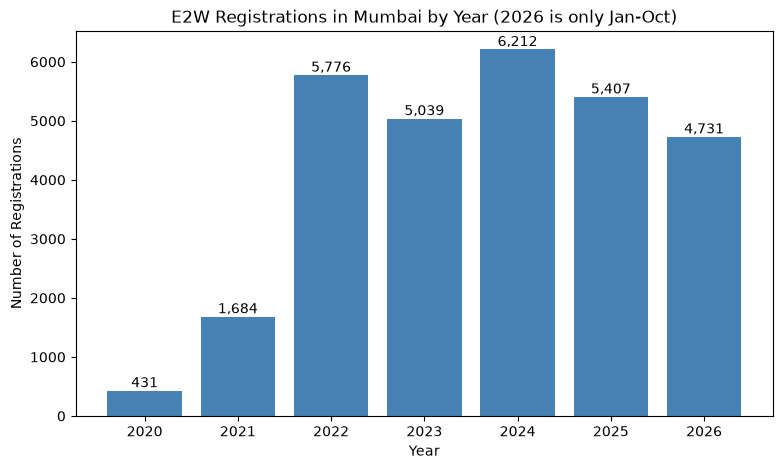

In [144]:
plt.figure(figsize=(9, 5))
plt.bar(yearly.index.astype(str), yearly.values, color='steelblue')

plt.title('E2W Registrations in Mumbai by Year (2026 is only Jan-Oct)')
plt.xlabel('Year')
plt.ylabel('Number of Registrations')

for i, v in enumerate(yearly.values):
    plt.text(i, v, f"{v:,}", ha='center', va='bottom')

plt.show()

**Insight:** In total 29,280 E2Ws were registered. Registrations grew very fast in 2021 and 2022, reached the highest in 2024 (6,212) and fell to 5,407 in 2025. 2026 has only 10 months (4,731), so it is not a full-year fall. The market is no longer growing quickly, so URJA EV has to win customers from other brands.

## How fast did it grow each year?

In [145]:
growth = (yearly.pct_change() * 100).round(1)
growth

Year
2020      NaN
2021    290.7
2022    243.0
2023    -12.8
2024     23.3
2025    -13.0
2026    -12.5
Name: EV_Total, dtype: float64

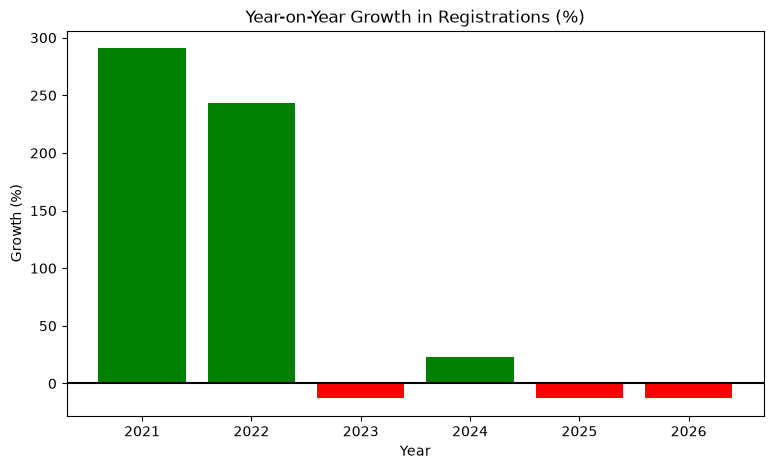

In [146]:
plt.figure(figsize=(9, 5))
plt.bar(growth.index.astype(str)[1:], growth.values[1:], color=['green' if g > 0 else 'red' for g in growth.values[1:]])
plt.axhline(0, color='black')

plt.title('Year-on-Year Growth in Registrations (%)')
plt.xlabel('Year')
plt.ylabel('Growth (%)')
plt.show()

**Insight:** Growth was 291% in 2021 and 243% in 2022, then -12.8% in 2023, +23.3% in 2024 and -13.0% in 2025. The 2026 bar (-12.5%) compares 10 months with a full year, so it is not a fair comparison. Annualised (4,731 x 12/10 = about 5,677), 2026 is about +5% over 2025.

### Which brands lead the market?

In [147]:
brand_total = reg.groupby('Brand')['EV_Total'].sum().sort_values(ascending=False)
brand_share = (brand_total / brand_total.sum() * 100).round(1)
brand_share.head(10)

Brand
Ola Electric            20.7
Ather Energy            12.3
Odysse                  11.4
Hero MotoCorp (Vida)     8.8
Ampere (Greaves)         7.9
BGauss                   7.4
Bajaj (Chetak)           4.9
TVS (iQube)              4.6
Hero Electric            4.5
Revolt                   4.0
Name: EV_Total, dtype: float64

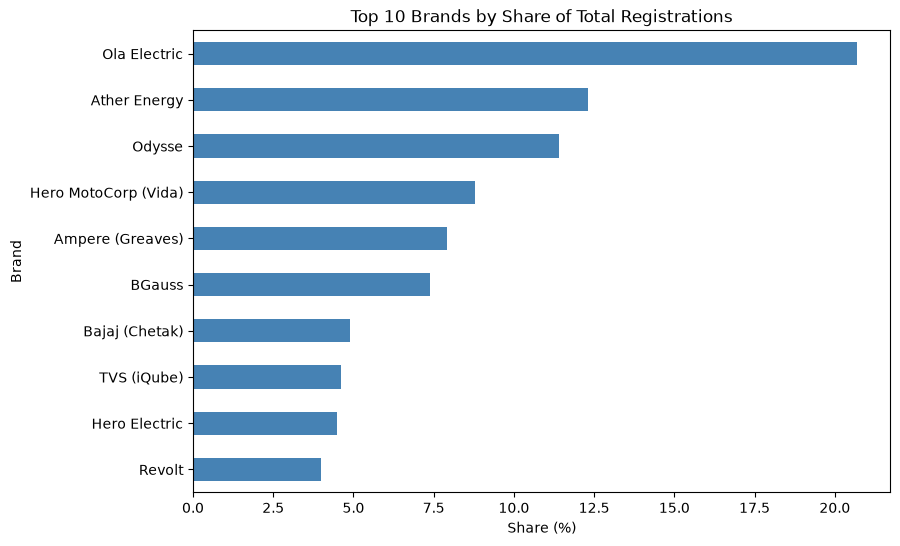

In [148]:
plt.figure(figsize=(9, 6))
brand_share.head(10).sort_values().plot(kind='barh', color='steelblue')

plt.title('Top 10 Brands by Share of Total Registrations')
plt.xlabel('Share (%)')
plt.show()

In [149]:
print("Top 3 brands share:", brand_share.head(3).sum().round(1), "%")
print("Top 5 brands share:", brand_share.head(5).sum().round(1), "%")

Top 3 brands share: 44.4 %
Top 5 brands share: 61.1 %


**Insight:** Ola Electric has the highest share (20.7%), then Ather Energy (12.3%) and Odysse (11.4%). The top 3 brands hold only 44.4% and the top 5 hold 61.1%, so no brand controls the market.

### How did brand shares change over the years?

In [150]:
brand_year = reg.pivot_table(index='Year', columns='Brand', values='EV_Total', aggfunc='sum').fillna(0)
share_year = brand_year.div(brand_year.sum(axis=1), axis=0) * 100

In [151]:
top5 = ['Ola Electric', 'Ather Energy', 'Hero MotoCorp (Vida)', 'TVS (iQube)', 'Bajaj (Chetak)']
share_year[top5].round(1)

Brand,Ola Electric,Ather Energy,Hero MotoCorp (Vida),TVS (iQube),Bajaj (Chetak)
Year,,,,,
2020,0.0,5.1,0.0,0.0,0.2
2021,1.0,28.8,0.0,0.1,0.1
2022,31.9,12.0,0.0,0.7,3.1
2023,32.3,18.7,4.5,4.8,4.5
2024,30.1,7.2,7.4,5.0,7.9
2025,7.5,8.6,14.7,5.7,6.4
2026,6.4,11.3,22.9,9.2,4.1


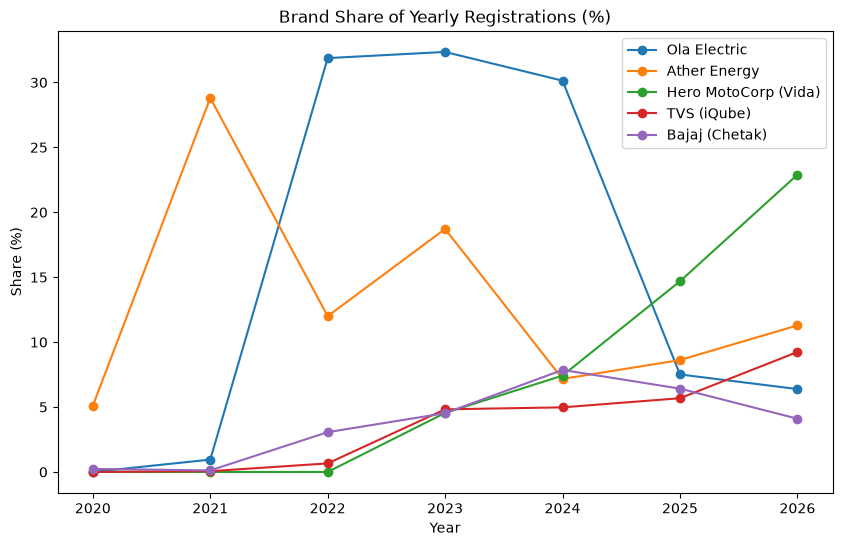

In [152]:
plt.figure(figsize=(10, 6))
for b in top5:
    plt.plot(share_year.index, share_year[b], marker='o', label=b)

plt.title('Brand Share of Yearly Registrations (%)')
plt.xlabel('Year')
plt.ylabel('Share (%)')
plt.legend()
plt.show()

**Insight:** Ola had about 30 to 32% share in 2022-2024 but fell to 7.5% in 2025 and 6.4% in 2026. Hero Vida grew from 4.5% in 2023 to 22.9% in 2026 and TVS grew to 9.2%. The leader keeps changing, so a new brand has a chance.

### EV start-ups vs legacy (old) companies

In [153]:
type_year = reg.pivot_table(index='Year', columns='Brand_Type', values='EV_Total', aggfunc='sum')
type_share = type_year.div(type_year.sum(axis=1), axis=0) * 100
type_share.round(1)

Brand_Type,EV start-up,Legacy OEM
Year,,
2020,99.8,0.2
2021,99.8,0.2
2022,96.1,3.9
2023,84.4,15.6
2024,72.5,27.5
2025,72.0,28.0
2026,61.6,38.4


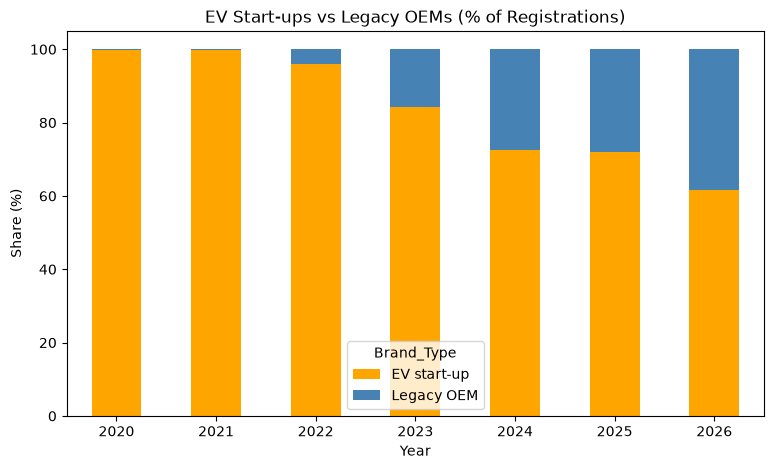

In [154]:
type_share.plot(kind='bar', stacked=True, figsize=(9, 5), color=['orange', 'steelblue'])

plt.title('EV Start-ups vs Legacy OEMs (% of Registrations)')
plt.xlabel('Year')
plt.ylabel('Share (%)')
plt.xticks(rotation=0)
plt.show()

In [155]:
(reg.groupby('Brand_Type')['EV_Total'].sum() / reg['EV_Total'].sum() * 100).round(1)

Brand_Type
EV start-up    79.3
Legacy OEM     20.7
Name: EV_Total, dtype: float64

**Insight:** In 2020-2021, 99.8% of registrations were from EV start-ups. The share of legacy companies (Hero, TVS, Bajaj, Honda) grew from 3.9% in 2022 to 38.4% in 2026. Overall, start-ups still hold 79.3%. Big old brands with strong dealer networks are taking share from the start-ups.

### Which RTO area has the most registrations?

In [156]:
area_total = reg.groupby('RTO_Area')['EV_Total'].sum()
area_total

RTO_Area
Mumbai Central (MH01)     8231
Mumbai East (MH03)       11390
Mumbai West (MH02)        9659
Name: EV_Total, dtype: int64

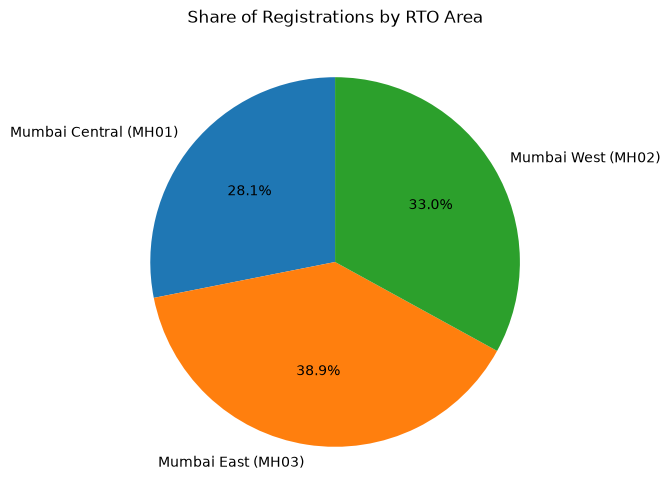

In [157]:
plt.figure(figsize=(6, 6))
plt.pie(area_total.values, labels=area_total.index, autopct='%1.1f%%', startangle=90)
plt.title('Share of Registrations by RTO Area')
plt.show()

In [158]:
area_year = reg.pivot_table(index='Year', columns='RTO_Area', values='EV_Total', aggfunc='sum')
area_year

RTO_Area,Mumbai Central (MH01),Mumbai East (MH03),Mumbai West (MH02)
Year,,,
2020,45,210,176
2021,545,486,653
2022,1995,1808,1973
2023,1661,1696,1682
2024,1502,2657,2053
2025,1327,2408,1672
2026,1156,2125,1450


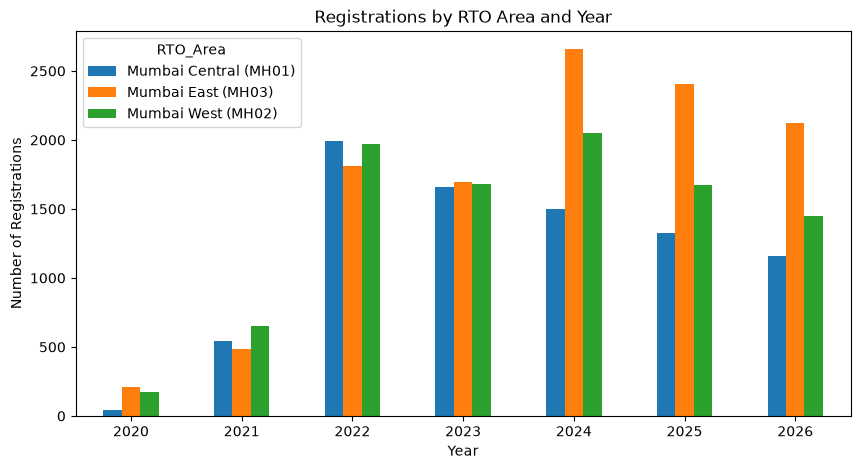

In [159]:
area_year.plot(kind='bar', figsize=(10, 5))

plt.title('Registrations by RTO Area and Year')
plt.xlabel('Year')
plt.ylabel('Number of Registrations')
plt.xticks(rotation=0)
plt.show()

**Insight:** Mumbai East has the highest share (38.9%), then Mumbai West (33.0%) and Mumbai Central (28.1%). Mumbai East has been the biggest area since 2024 (2,657 in 2024). Mumbai Central is the smallest and has fallen from 1,995 in 2022 to 1,156 in 2026 (10 months).

### Which brands are strong in which area?

In [160]:
top8 = brand_share.head(8).index
brand_area = reg.pivot_table(index='Brand', columns='RTO_Area', values='EV_Total', aggfunc='sum').fillna(0)
brand_area_share = brand_area.div(brand_area.sum(axis=0), axis=1) * 100
brand_area_share.loc[top8].round(1)

RTO_Area,Mumbai Central (MH01),Mumbai East (MH03),Mumbai West (MH02)
Brand,,,
Ola Electric,27.9,17.5,18.4
Ather Energy,16.2,9.9,11.6
Odysse,0.1,25.3,4.8
Hero MotoCorp (Vida),10.3,9.5,6.5
Ampere (Greaves),6.7,1.8,16.0
BGauss,7.4,6.4,8.6
Bajaj (Chetak),4.6,4.9,5.2
TVS (iQube),7.2,3.3,3.8


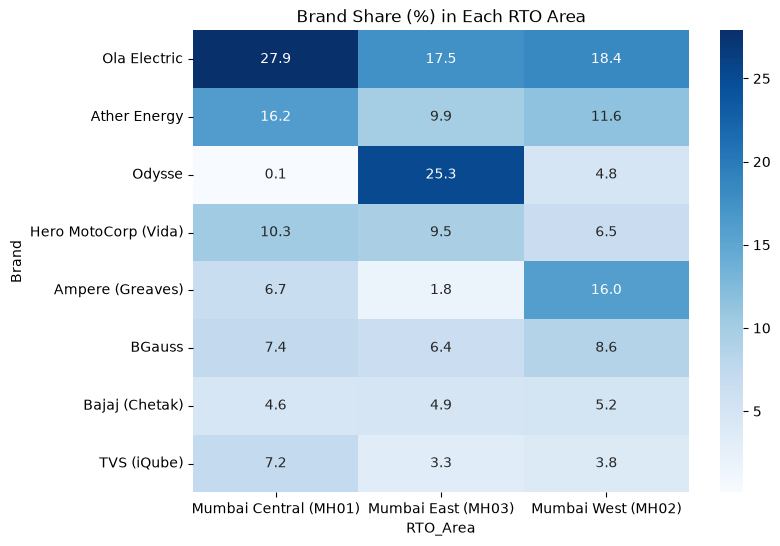

In [161]:
plt.figure(figsize=(8, 6))
sns.heatmap(brand_area_share.loc[top8], annot=True, fmt='.1f', cmap='Blues')
plt.title('Brand Share (%) in Each RTO Area')
plt.show()

**Insight:** Brand strength is different in each area. Odysse is 25.3% of Mumbai East but only 4.8% in West and 0.1% in Central. Ola is strongest in Central (27.9%) and Ampere in West (16.0%). So a big part of East's demand depends on one brand.

## 4B. Charging stations (real data)

In [162]:
stations_by_area = chg[chg['has_coords']]['RTO_Zone'].value_counts()
stations_by_area

RTO_Zone
Mumbai East (MH03)       24
Mumbai West (MH02)       22
Mumbai Central (MH01)    13
Name: count, dtype: int64

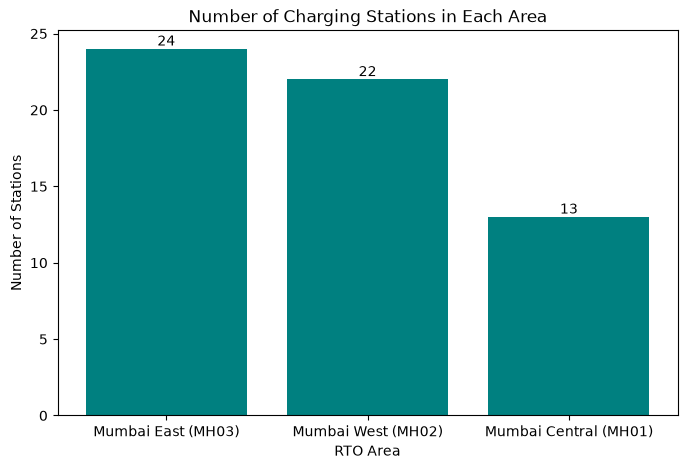

In [163]:
plt.figure(figsize=(8, 5))
plt.bar(stations_by_area.index, stations_by_area.values, color='teal')

for i, v in enumerate(stations_by_area.values):
    plt.text(i, v, v, ha='center', va='bottom')

plt.title('Number of Charging Stations in Each Area')
plt.xlabel('RTO Area')
plt.ylabel('Number of Stations')
plt.show()

In [164]:
infra = pd.DataFrame({'E2Ws': reg.groupby('RTO_Area')['EV_Total'].sum(),
                      'Stations': stations_by_area})
infra['Stations per 100 E2Ws'] = (infra['Stations'] / infra['E2Ws'] * 100).round(2)
infra

,E2Ws,Stations,Stations per 100 E2Ws
Mumbai Central (MH01),8231,13,0.16
Mumbai East (MH03),11390,24,0.21
Mumbai West (MH02),9659,22,0.23


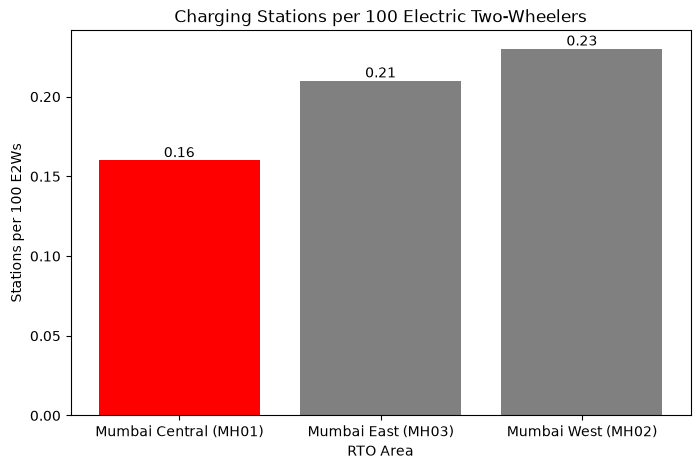

In [165]:
plt.figure(figsize=(8, 5))
plt.bar(infra.index, infra['Stations per 100 E2Ws'], color=['red', 'gray', 'gray'])

for i, v in enumerate(infra['Stations per 100 E2Ws']):
    plt.text(i, v, v, ha='center', va='bottom')

plt.title('Charging Stations per 100 Electric Two-Wheelers')
plt.xlabel('RTO Area')
plt.ylabel('Stations per 100 E2Ws')
plt.show()

**Insight:** There are 60 charging stations for 29,280 E2Ws, about **0.20 stations per 100 E2Ws**, which is very low. Mumbai Central is the weakest (13 stations, 0.16 per 100 E2Ws), while West (0.23) and East (0.21) are a little better. Public charging is not enough, so URJA EV should offer home charging or battery swapping.

## 4C. Customer survey (synthetic data)
### Age, income, budget and commute

In [166]:
sv[['Age', 'Effective_Income', 'Budget_INR', 'Daily_Commute_km']].describe().round(0)

,Age,Effective_Income,Budget_INR,Daily_Commute_km
count,397.0,397.0,397.0,397.0
mean,34.0,65544.0,128652.0,15.0
std,8.0,35910.0,65502.0,7.0
min,21.0,6000.0,40000.0,4.0
25%,28.0,43000.0,80000.0,10.0
50%,33.0,59000.0,115000.0,14.0
75%,39.0,85000.0,170000.0,18.0
max,65.0,265000.0,320000.0,50.0


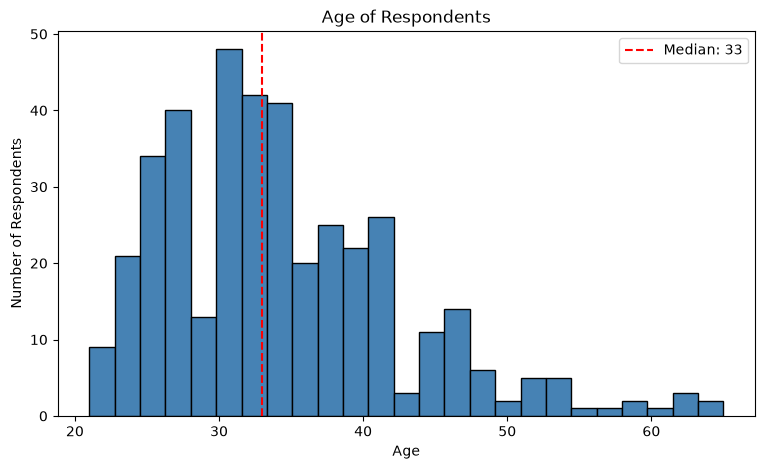

In [167]:
plt.figure(figsize=(9, 5))
plt.hist(sv['Age'], bins=25, color='steelblue', edgecolor='black')
plt.axvline(sv['Age'].median(), color='red', linestyle='--', label=f"Median: {sv['Age'].median():.0f}")

plt.title('Age of Respondents')
plt.xlabel('Age')
plt.ylabel('Number of Respondents')
plt.legend()
plt.show()

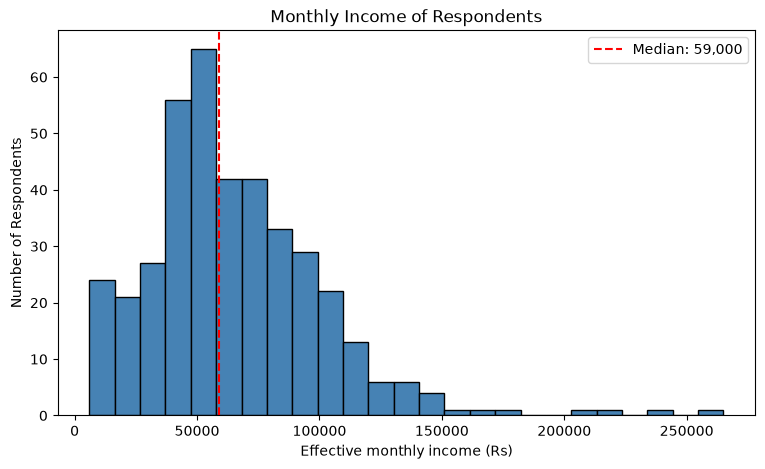

In [168]:
plt.figure(figsize=(9, 5))
plt.hist(sv['Effective_Income'], bins=25, color='steelblue', edgecolor='black')
plt.axvline(sv['Effective_Income'].median(), color='red', linestyle='--', label=f"Median: {sv['Effective_Income'].median():,.0f}")

plt.title('Monthly Income of Respondents')
plt.xlabel('Effective monthly income (Rs)')
plt.ylabel('Number of Respondents')
plt.legend()
plt.show()

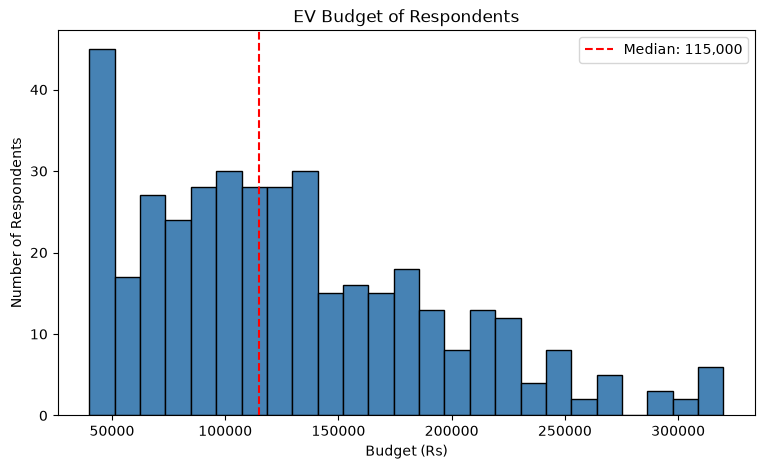

In [169]:
plt.figure(figsize=(9, 5))
plt.hist(sv['Budget_INR'], bins=25, color='steelblue', edgecolor='black')
plt.axvline(sv['Budget_INR'].median(), color='red', linestyle='--', label=f"Median: {sv['Budget_INR'].median():,.0f}")

plt.title('EV Budget of Respondents')
plt.xlabel('Budget (Rs)')
plt.ylabel('Number of Respondents')
plt.legend()
plt.show()

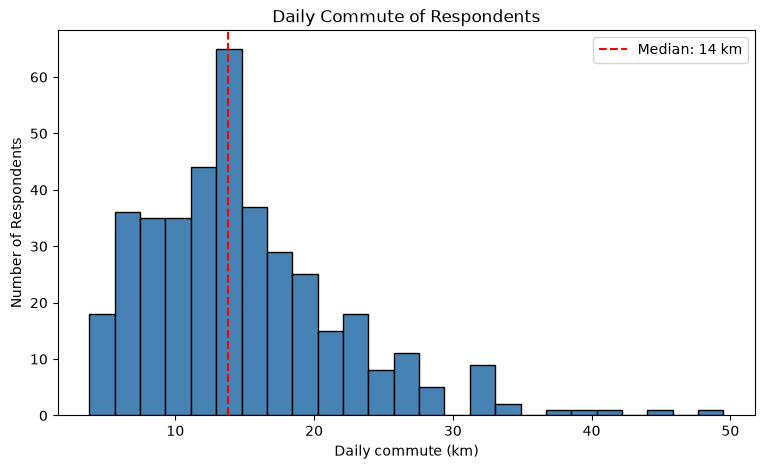

In [170]:
plt.figure(figsize=(9, 5))
plt.hist(sv['Daily_Commute_km'], bins=25, color='steelblue', edgecolor='black')
plt.axvline(sv['Daily_Commute_km'].median(), color='red', linestyle='--', label=f"Median: {sv['Daily_Commute_km'].median():.0f} km")

plt.title('Daily Commute of Respondents')
plt.xlabel('Daily commute (km)')
plt.ylabel('Number of Respondents')
plt.legend()
plt.show()

**Insight:**
- **Age:** the median age is 33 and the middle 50% of respondents are between 28 and 39. Only about 5% are above 50.
- **Income:** the median monthly income is about Rs 59,000 (middle 50%: Rs 43,000 to Rs 85,000).
- **Budget:** the median EV budget is Rs 1.15 lakh (middle 50%: Rs 80,000 to Rs 1.7 lakh).
- **Commute:** the median daily commute is 14 km and 74% of respondents travel 18 km or less, so a range of 80 to 100 km is enough for most.

### Do people want an EV?

In [173]:
interest_counts = sv['EV_Interest'].value_counts()
interest_counts

EV_Interest
Yes           245
Maybe         105
No             40
Not stated      7
Name: count, dtype: int64

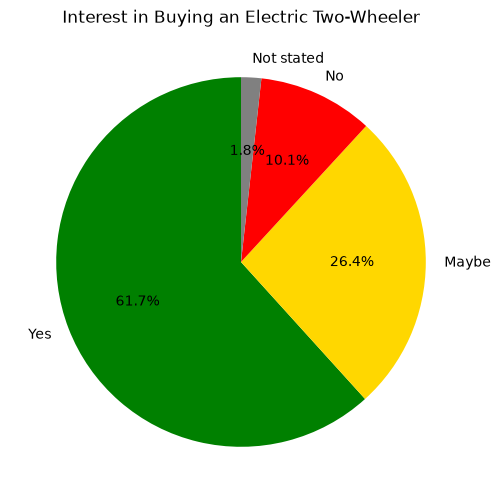

In [174]:
plt.figure(figsize=(6, 6))
plt.pie(interest_counts.values, labels=interest_counts.index, autopct='%1.1f%%', startangle=90,
        colors=['green', 'gold', 'red', 'gray'])
plt.title('Interest in Buying an Electric Two-Wheeler')
plt.show()

**Insight:** 61.7% say Yes, 26.4% say Maybe and 10.1% say No (62.8% Yes among those who answered). Interest is high, but remember this is synthetic data.

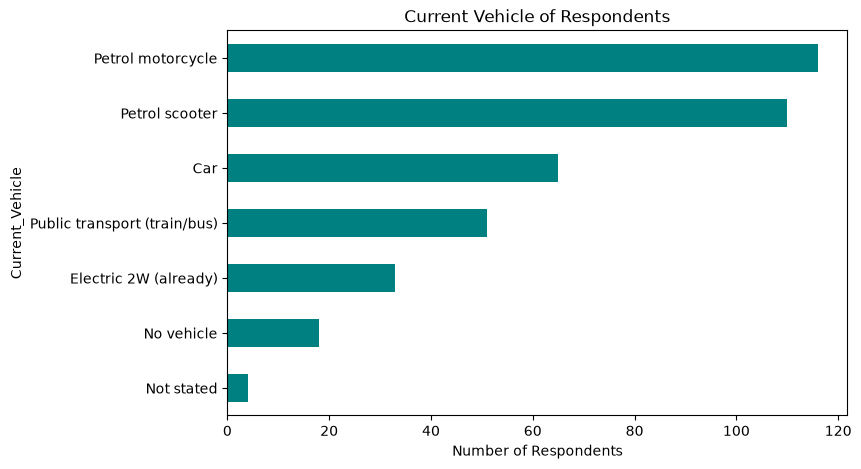

In [175]:
sv['Current_Vehicle'].value_counts().sort_values().plot(kind='barh', figsize=(8, 5), color='teal')
plt.title('Current Vehicle of Respondents')
plt.xlabel('Number of Respondents')
plt.show()

**Insight:** 29.2% ride a petrol motorcycle and 27.7% ride a petrol scooter, so about 57% use a petrol two-wheeler and can switch to electric. Another 16.4% use a car, 12.8% use public transport and 8.3% already own an electric two-wheeler.

In [176]:
home_counts = sv['Home_Charging_Possible'].value_counts()
home_counts

Home_Charging_Possible
No (shared/street parking)    194
Yes (own/society parking)     189
Not stated                     14
Name: count, dtype: int64

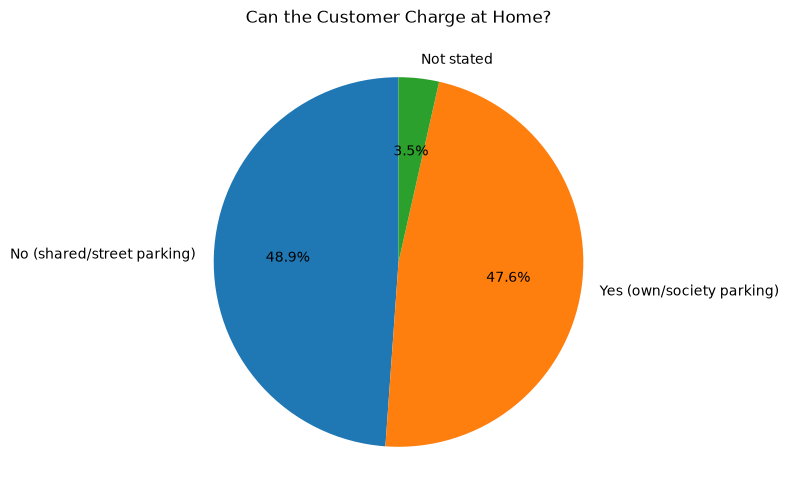

In [177]:
plt.figure(figsize=(6, 6))
plt.pie(home_counts.values, labels=home_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Can the Customer Charge at Home?')
plt.show()

**Insight:** Only 47.6% can charge at home, while 48.9% cannot (they use street or shared parking). About half of the customers will depend on public charging, where we saw there are very few stations.

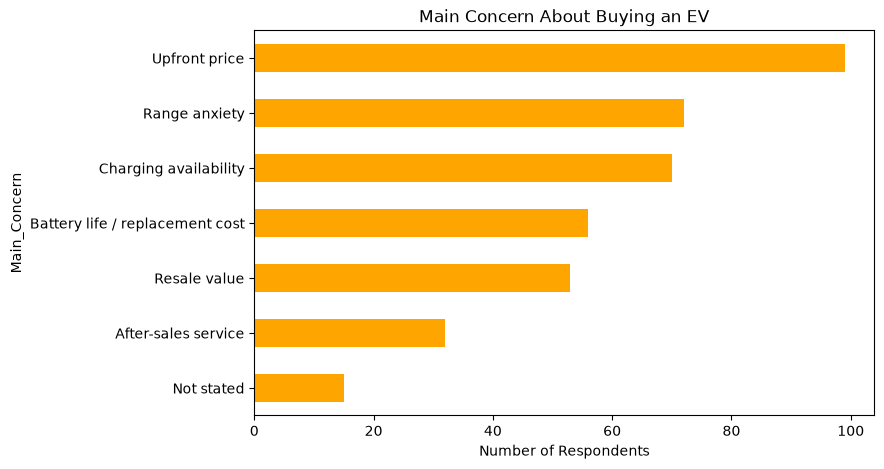

In [178]:
sv['Main_Concern'].value_counts().sort_values().plot(kind='barh', figsize=(8, 5), color='orange')
plt.title('Main Concern About Buying an EV')
plt.xlabel('Number of Respondents')
plt.show()

**Insight:** Upfront price is the biggest worry (24.9%), then range anxiety (18.1%) and charging availability (17.6%). Battery life (14.1%) and resale value (13.4%) follow, and after-sales service is the smallest (8.1%).

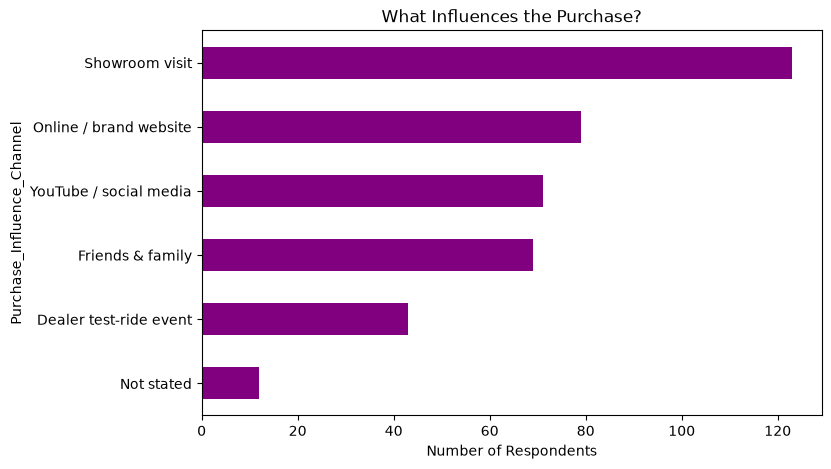

In [179]:
sv['Purchase_Influence_Channel'].value_counts().sort_values().plot(kind='barh', figsize=(8, 5), color='purple')
plt.title('What Influences the Purchase?')
plt.xlabel('Number of Respondents')
plt.show()

**Insight:** Showroom visit is the most common influence (31.0%), then online / brand website (19.9%), YouTube / social media (17.9%) and friends and family (17.4%). Dealer test-ride events are the smallest (10.8%).

### What decides interest in an EV?

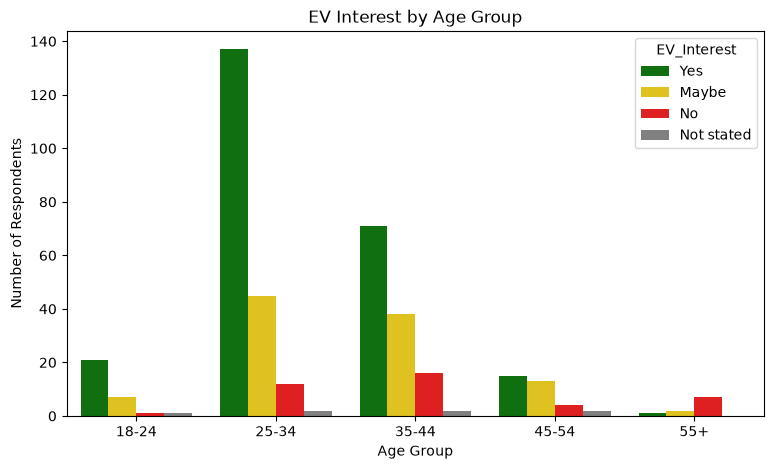

In [180]:
plt.figure(figsize=(9, 5))
sns.countplot(data=sv, x='Age_Group', hue='EV_Interest', order=['18-24', '25-34', '35-44', '45-54', '55+'],
              hue_order=['Yes', 'Maybe', 'No', 'Not stated'], palette=['green', 'gold', 'red', 'gray'])
plt.title('EV Interest by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Respondents')
plt.show()

In [181]:
pd.crosstab(sv['Age_Group'], sv['EV_Interest'], normalize='index').mul(100).round(0)

EV_Interest,Maybe,No,Not stated,Yes
Age_Group,,,,
18-24,23.0,3.0,3.0,70.0
25-34,23.0,6.0,1.0,70.0
35-44,30.0,13.0,2.0,56.0
45-54,38.0,12.0,6.0,44.0
55+,20.0,70.0,0.0,10.0


**Insight:** Interest goes down as age goes up: 70% Yes for ages 18-34, 56% for 35-44 and 44% for 45-54. The 55+ group has only 10% Yes, but it has very few respondents. The best customers are young people below 35.

In [182]:
vehicle_interest = pd.crosstab(sv['Current_Vehicle'], sv['EV_Interest'], normalize='index').mul(100).round(0)
vehicle_interest = vehicle_interest[['Yes', 'Maybe', 'No']].sort_values('Yes')
vehicle_interest

EV_Interest,Yes,Maybe,No
Current_Vehicle,,,
No vehicle,22.0,22.0,56.0
Public transport (train/bus),39.0,43.0,16.0
Car,42.0,38.0,14.0
Not stated,50.0,25.0,25.0
Petrol scooter,72.0,23.0,5.0
Petrol motorcycle,72.0,21.0,6.0
Electric 2W (already),88.0,12.0,0.0


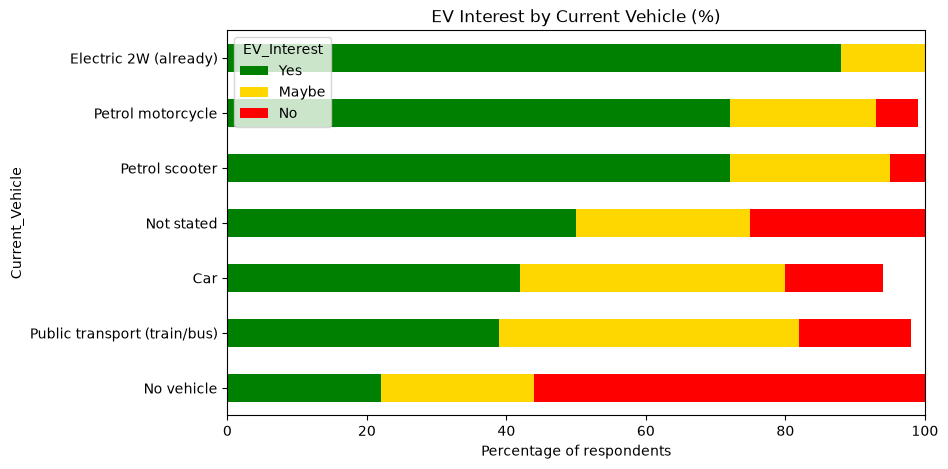

In [183]:
vehicle_interest.plot(kind='barh', stacked=True, figsize=(9, 5), color=['green', 'gold', 'red'])
plt.title('EV Interest by Current Vehicle (%)')
plt.xlabel('Percentage of respondents')
plt.show()

**Insight:** Petrol scooter (72% Yes) and petrol motorcycle (72% Yes) owners are the most interested, after people who already own an electric two-wheeler (88%). Car owners (42%), public transport users (39%) and people with no vehicle (22%) are much less interested. URJA EV should first target petrol two-wheeler owners.

In [184]:
prof_interest = pd.crosstab(sv['Profession'], sv['EV_Interest'], normalize='index').mul(100).round(0)
prof_interest['Respondents'] = sv['Profession'].value_counts()
prof_interest.sort_values('Yes', ascending=False)

EV_Interest,Maybe,No,Not stated,Yes,Respondents
Profession,,,,,
Intern / Fresher,0.0,0.0,0.0,100.0,3
Gig / Delivery,10.0,7.0,0.0,83.0,29
IT / Tech,14.0,3.0,6.0,76.0,63
Not stated,26.0,11.0,0.0,63.0,19
Homemaker,20.0,18.0,0.0,62.0,40
Salaried (govt),24.0,16.0,0.0,60.0,45
Salaried (private),31.0,11.0,3.0,56.0,117
Business / Self-employed,42.0,7.0,0.0,51.0,76
Part-time / Gig,0.0,50.0,0.0,50.0,2


**Insight:** Gig / delivery workers (83% Yes, 29 respondents) and IT / tech people (76%, 63 respondents) are the most interested. Private salaried employees, the biggest group (117 respondents), are at 56% and business owners at 51%. Ignore the professions that have only 1 to 3 respondents.

In [185]:
concern_budget = pd.crosstab(sv['Budget_Band'], sv['Main_Concern'], normalize='index').mul(100).round(0)
concern_budget

Main_Concern,After-sales service,Battery life / replacement cost,Charging availability,Not stated,Range anxiety,Resale value,Upfront price
Budget_Band,,,,,,,
<80k,12.0,16.0,10.0,4.0,9.0,12.0,39.0
80k-1.2L,6.0,14.0,18.0,2.0,21.0,16.0,25.0
1.2L-1.6L,7.0,11.0,21.0,8.0,21.0,15.0,18.0
1.6L-2.2L,7.0,14.0,25.0,1.0,21.0,14.0,19.0
2.2L+,8.0,17.0,22.0,6.0,31.0,8.0,8.0


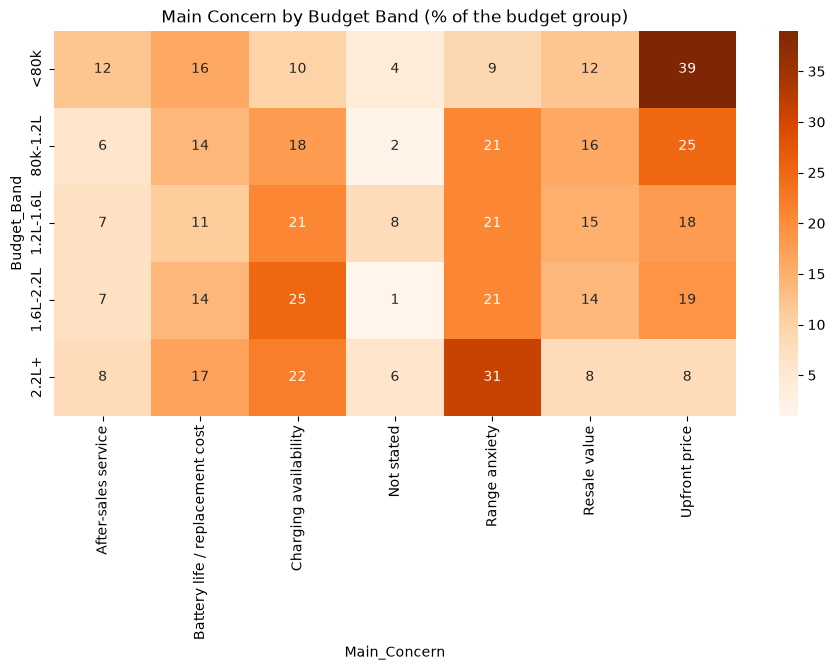

In [186]:
plt.figure(figsize=(11, 5))
sns.heatmap(concern_budget, annot=True, fmt='.0f', cmap='Oranges')
plt.title('Main Concern by Budget Band (% of the budget group)')
plt.show()

**Insight:** The low-budget group (below Rs 80,000) worries mostly about the upfront price (39%) and little about charging (10%). The high-budget group (Rs 2.2 lakh and above) worries most about range (31%) and charging (22%), and only 8% about price. So the message for premium buyers is range and charging, and for low-budget buyers it is price and EMI.

In [187]:
channel_interest = pd.crosstab(sv['Purchase_Influence_Channel'], sv['EV_Interest'], normalize='index').mul(100).round(0)
channel_interest['Respondents'] = sv['Purchase_Influence_Channel'].value_counts()
channel_interest.sort_values('Yes', ascending=False)

EV_Interest,Maybe,No,Not stated,Yes,Respondents
Purchase_Influence_Channel,,,,,
Dealer test-ride event,23.0,2.0,0.0,74.0,43
Online / brand website,19.0,13.0,0.0,68.0,79
YouTube / social media,23.0,11.0,3.0,63.0,71
Friends & family,28.0,9.0,1.0,62.0,69
Showroom visit,33.0,11.0,2.0,53.0,123
Not stated,33.0,8.0,8.0,50.0,12


**Insight:** Customers influenced by dealer test-ride events show the highest interest (74% Yes), then online / brand website (68%), YouTube / social media (63%) and friends and family (62%). Showroom visitors are the lowest (53%). Test rides and online channels are a good way to reach interested customers.

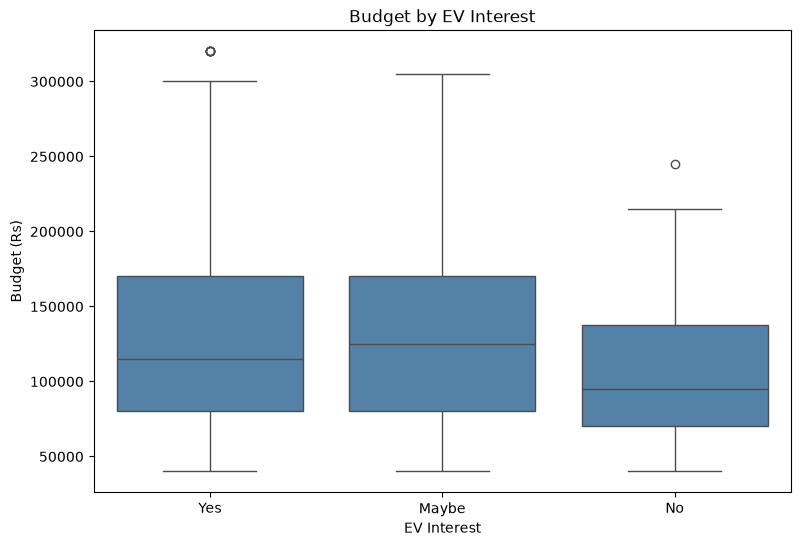

In [188]:
plt.figure(figsize=(9, 6))
sns.boxplot(data=sv, x='EV_Interest', y='Budget_INR', order=['Yes', 'Maybe', 'No'], color='steelblue')
plt.title('Budget by EV Interest')
plt.xlabel('EV Interest')
plt.ylabel('Budget (Rs)')
plt.show()

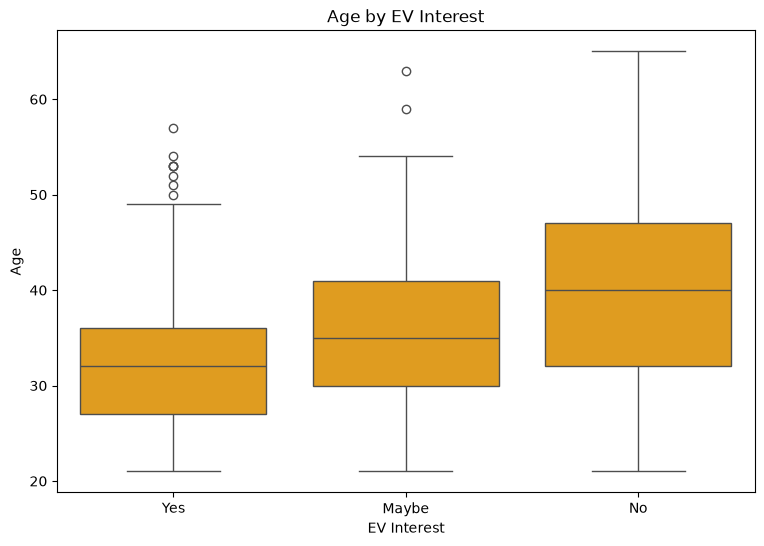

In [189]:
plt.figure(figsize=(9, 6))
sns.boxplot(data=sv, x='EV_Interest', y='Age', order=['Yes', 'Maybe', 'No'], color='orange')
plt.title('Age by EV Interest')
plt.xlabel('EV Interest')
plt.ylabel('Age')
plt.show()

**Insight:** The median budget is similar for people who say Yes (Rs 1.15 lakh) and Maybe (Rs 1.25 lakh), and a little lower for No (Rs 95,000), so a higher budget does not mean more interest. The median age is 32 for Yes, 35 for Maybe and 40 for No, so people who want an EV are younger.

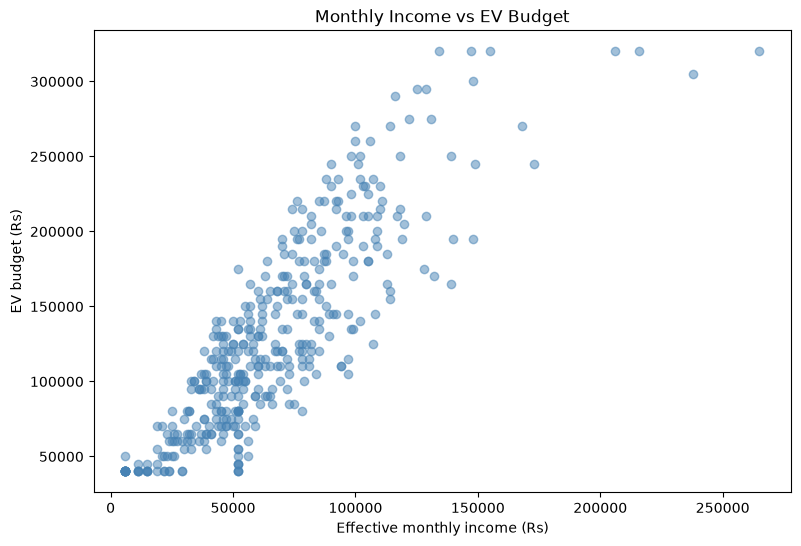

In [190]:
plt.figure(figsize=(9, 6))
plt.scatter(sv['Effective_Income'], sv['Budget_INR'], alpha=0.5, color='steelblue')
plt.title('Monthly Income vs EV Budget')
plt.xlabel('Effective monthly income (Rs)')
plt.ylabel('EV budget (Rs)')
plt.show()

**Insight:** The dots go up from left to right, so people with a higher income have a higher budget. The relation is strong (correlation 0.85, see the heatmap below).

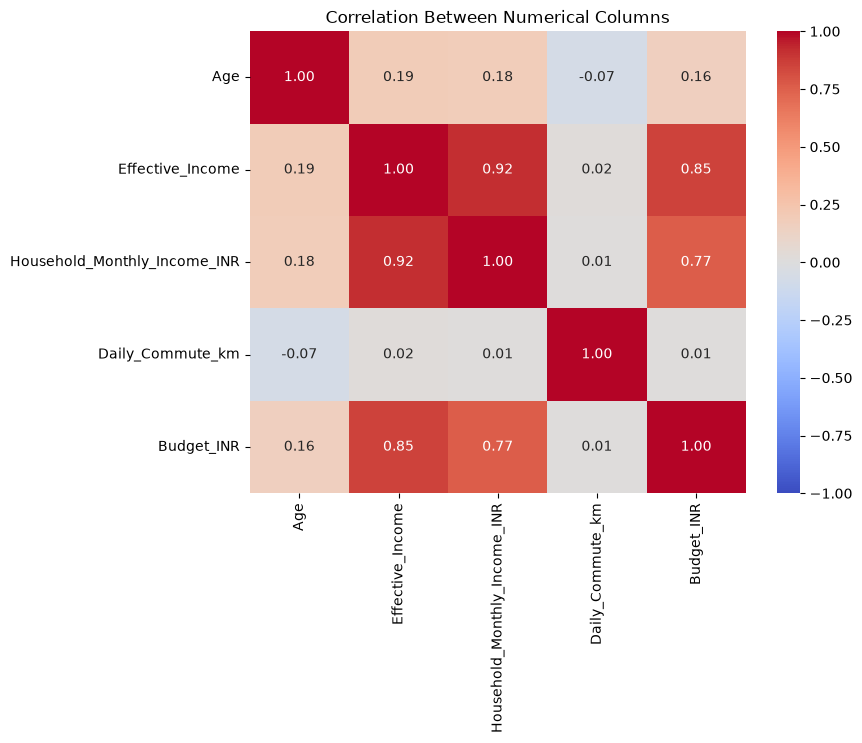

In [191]:
num_cols = ['Age', 'Effective_Income', 'Household_Monthly_Income_INR', 'Daily_Commute_km', 'Budget_INR']
corr = sv[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Between Numerical Columns')
plt.show()

**Insight:** Effective income and budget are strongly related (0.85), and so are household income and budget (0.77). Age has a weak positive relation with income (0.19) and budget (0.16). Daily commute is not related to any other column (values close to 0).

In [192]:
area_survey = sv.groupby('RTO_Area').agg(respondents=('Respondent_ID', 'count'),
                                         yes_percent=('EV_Interest', lambda x: (x == 'Yes').mean() * 100),
                                         median_budget=('Budget_INR', 'median'))
area_survey['yes_percent'] = area_survey['yes_percent'].round(1)
area_survey

,respondents,yes_percent,median_budget
RTO_Area,,,
Mumbai Central (MH01),57,49.1,120000.0
Mumbai East (MH03),151,62.9,115000.0
Mumbai West (MH02),189,64.6,120000.0


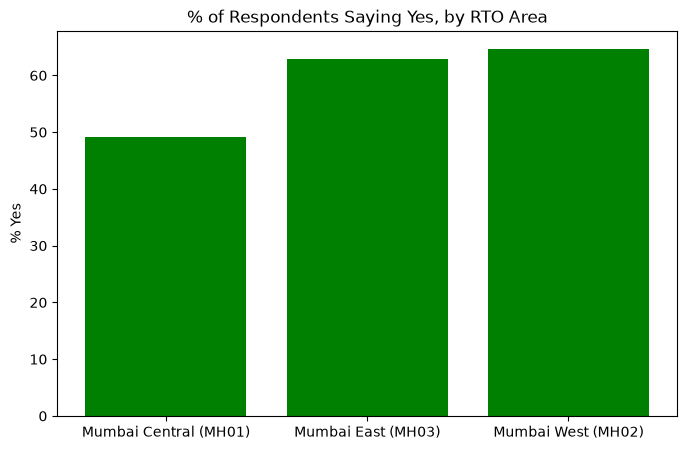

In [193]:
plt.figure(figsize=(8, 5))
plt.bar(area_survey.index, area_survey['yes_percent'], color='green')
plt.title('% of Respondents Saying Yes, by RTO Area')
plt.ylabel('% Yes')
plt.show()

**Insight:** The share of Yes answers is higher in Mumbai West (64.6%) and East (62.9%) than in Mumbai Central (49.1%). The survey area was made up in the synthetic data, so this result is only for practice.

# Part D: Customer Segmentation (K-Means)
We group the respondents into segments using **age, income, budget and profession**, as written in the proposal.

In [194]:
# 0 = student / fresher, 1 = gig, homemaker, retired, not stated, 2 = salaried, 3 = IT or business
sv['Prof_Code'] = sv['Profession'].replace({'Student': 0, 'Intern / Fresher': 0,
                                            'Part-time / Gig': 1, 'Gig / Delivery': 1, 'Homemaker': 1, 'Retired': 1, 'Not stated': 1,
                                            'Salaried (private)': 2, 'Salaried (govt)': 2,
                                            'IT / Tech': 3, 'Business / Self-employed': 3}).astype(int)
sv['Prof_Code'].value_counts()

Prof_Code
2    162
3    139
1     91
0      5
Name: count, dtype: int64

In [195]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [196]:
# scale the columns so that income (big numbers) does not dominate age (small numbers)
cluster_data = sv[['Age', 'Effective_Income', 'Budget_INR', 'Prof_Code']]
X = StandardScaler().fit_transform(cluster_data)

In [197]:
inertia = []
silhouette = []

for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    model.fit(X)
    inertia.append(model.inertia_)
    silhouette.append(silhouette_score(X, model.labels_))

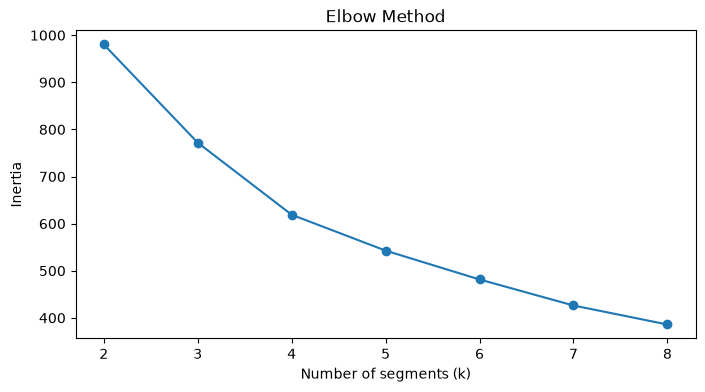

In [198]:
plt.figure(figsize=(8, 4))
plt.plot(range(2, 9), inertia, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of segments (k)')
plt.ylabel('Inertia')
plt.show()

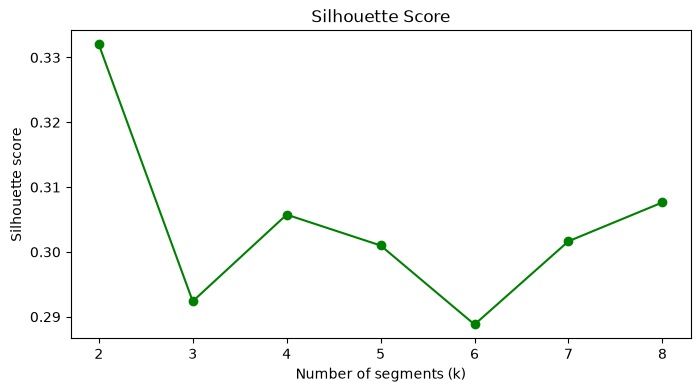

In [199]:
plt.figure(figsize=(8, 4))
plt.plot(range(2, 9), silhouette, marker='o', color='green')
plt.title('Silhouette Score')
plt.xlabel('Number of segments (k)')
plt.ylabel('Silhouette score')
plt.show()

**Insight:** The elbow curve has no sharp bend, and the silhouette score is highest for 2 segments (0.33). Two segments are too few for marketing, and 4 segments score almost the same (0.31), so we use **4 segments**.

In [200]:
model = KMeans(n_clusters=4, n_init=10, random_state=42)
sv['Segment'] = model.fit_predict(X)
sv['Segment'].value_counts().sort_index()

Segment
0     84
1     82
2    157
3     74
Name: count, dtype: int64

In [201]:
segment_profile = sv.groupby('Segment').agg(respondents=('Respondent_ID', 'count'),
                                            avg_age=('Age', 'mean'),
                                            median_income=('Effective_Income', 'median'),
                                            median_budget=('Budget_INR', 'median'),
                                            avg_commute=('Daily_Commute_km', 'mean'),
                                            yes_percent=('EV_Interest', lambda x: (x == 'Yes').mean() * 100))
segment_profile['size_percent'] = segment_profile['respondents'] / segment_profile['respondents'].sum() * 100
segment_profile.round(1)

,respondents,avg_age,median_income,median_budget,avg_commute,yes_percent,size_percent
Segment,,,,,,,
0,84,34.3,104500.0,210000.0,16.1,70.2,21.2
1,82,30.7,26500.0,50000.0,16.2,70.7,20.7
2,157,30.7,54000.0,110000.0,14.1,63.1,39.5
3,74,46.6,70000.0,125000.0,13.8,39.2,18.6


In [202]:
# the most common profession, concern and vehicle of each segment
for seg in range(4):
    d = sv[sv['Segment'] == seg]
    print("Segment", seg)
    print("  Profession:", d['Profession'].value_counts().index[0])
    print("  Concern   :", d['Main_Concern'].value_counts().index[0])
    print("  Vehicle   :", d['Current_Vehicle'].value_counts().index[0])

Segment 0
  Profession: IT / Tech
  Concern   : Range anxiety
  Vehicle   : Car
Segment 1
  Profession: Homemaker
  Concern   : Upfront price
  Vehicle   : Petrol scooter
Segment 2
  Profession: Salaried (private)
  Concern   : Upfront price
  Vehicle   : Petrol scooter
Segment 3
  Profession: Salaried (private)
  Concern   : Upfront price
  Vehicle   : Petrol scooter


**Insight:** Segment 0 is rich and IT-heavy (budget Rs 2.1 lakh, worried about range). Segment 1 has a very low budget (Rs 50,000). Segment 2 is the biggest (157 respondents, budget Rs 1.1 lakh, salaried scooter riders worried about price). Segment 3 is older (average age 46.6) and has the lowest interest (39.2% Yes).

In [203]:
segment_names = {0: 'Affluent Tech Professionals', 1: 'Budget-Conscious Young Riders',
                 2: 'Core Salaried Scooter Switchers', 3: 'Cautious Mid-Career Riders'}

segment_profile['name'] = segment_profile.index.map(segment_names)
sv['Segment_Name'] = sv['Segment'].map(segment_names)
segment_profile[['name', 'size_percent', 'median_income', 'median_budget', 'yes_percent']].round(1)

                                    name  size_percent  median_income  median_budget  yes_percent
Segment                                                                                          
0            Affluent Tech Professionals          21.2       104500.0       210000.0         70.2
1          Budget-Conscious Young Riders          20.7        26500.0        50000.0         70.7
2        Core Salaried Scooter Switchers          39.5        54000.0       110000.0         63.1
3             Cautious Mid-Career Riders          18.6        70000.0       125000.0         39.2

**Naming the segments:** the names below match the table above. Segment 2 (157 respondents, budget Rs 1.1 lakh) is *Core Salaried Scooter Switchers* and segment 3 (average age 46.6, 39% Yes) is *Cautious Mid-Career Riders*. If you change `random_state` or the number of segments, the numbers change, so check the table again.

In [204]:
size_score = (segment_profile['respondents'] - segment_profile['respondents'].min()) / (segment_profile['respondents'].max() - segment_profile['respondents'].min())
budget_score = (segment_profile['median_budget'] - segment_profile['median_budget'].min()) / (segment_profile['median_budget'].max() - segment_profile['median_budget'].min())
interest_score = (segment_profile['yes_percent'] - segment_profile['yes_percent'].min()) / (segment_profile['yes_percent'].max() - segment_profile['yes_percent'].min())

segment_profile['score'] = (0.3 * size_score + 0.3 * budget_score + 0.4 * interest_score).round(3)

In [205]:
segment_profile.sort_values('score', ascending=False)[['name', 'size_percent', 'median_budget', 'yes_percent', 'score']].round(2)

                                    name  size_percent  median_budget  yes_percent  score
Segment                                                                                  
0            Affluent Tech Professionals         21.16       210000.0        70.24   0.73
2        Core Salaried Scooter Switchers         39.55       110000.0        63.06   0.72
1          Budget-Conscious Young Riders         20.65        50000.0        70.73   0.43
3             Cautious Mid-Career Riders         18.64       125000.0        39.19   0.14

**Insight:** Affluent Tech Professionals score highest (0.73), and Core Salaried Scooter Switchers are almost the same (0.72) and are the biggest group (39.5%). Budget-Conscious Young Riders (0.43) are interested but their budget is too low, and Cautious Mid-Career Riders score lowest (0.14). URJA EV can target the first two segments.

In [206]:
plt.figure(figsize=(9, 6))
plt.scatter(segment_profile['median_budget'], segment_profile['yes_percent'], s=segment_profile['respondents'] * 8, alpha=0.6)

for seg in segment_profile.index:
    plt.text(segment_profile.loc[seg, 'median_budget'], segment_profile.loc[seg, 'yes_percent'], segment_profile.loc[seg, 'name'], ha='center', fontsize=9)

plt.title('Segments: Budget vs Interest (bubble size = number of respondents)')
plt.xlabel('Median budget (Rs)')
plt.ylabel('% saying Yes to EV')
plt.show()

# Part E: Launch Scorecard and Area Ranking
The proposal asks for a launch recommendation, so we check 6 simple tests (the pass levels are our own assumptions) and rank the three RTO areas.

**EV share of two-wheelers:** our data has no petrol two-wheeler registrations, so the EV share cannot be calculated. The three values below are **assumed** (taken from the project guide). Say this in your report, or replace them with real numbers from Vahan (E2Ws divided by all two-wheelers).

In [ ]:
ev_share = pd.DataFrame({'RTO_Area': ['Mumbai Central (MH01)', 'Mumbai East (MH03)', 'Mumbai West (MH02)'],
                         'EV_Share_Percent': [1.15, 1.55, 1.83]})
ev_share

                RTO_Area  EV_Share_Percent
0  Mumbai Central (MH01)              1.15
1     Mumbai East (MH03)              1.55
2     Mumbai West (MH02)              1.83

In [ ]:
# Area ranking: demand, charging and interest (1 = best)
answered = sv[sv['EV_Interest'] != 'Not stated']
yes_area = answered.groupby('RTO_Area')['EV_Interest'].apply(lambda x: (x == 'Yes').mean() * 100).round(1)

area_rank = infra.reset_index().rename(columns={'index': 'RTO_Area'})
area_rank['Yes_percent'] = area_rank['RTO_Area'].map(yes_area)
area_rank['Rank_Demand'] = area_rank['E2Ws'].rank(ascending=False).astype(int)
area_rank['Rank_Charging'] = area_rank['Stations per 100 E2Ws'].rank(ascending=False).astype(int)
area_rank['Rank_Interest'] = area_rank['Yes_percent'].rank(ascending=False).astype(int)
area_rank['Total_Rank'] = area_rank['Rank_Demand'] + area_rank['Rank_Charging'] + area_rank['Rank_Interest']
area_rank

                RTO_Area   E2Ws  Stations  Stations per 100 E2Ws  Yes_percent  Rank_Demand  Rank_Charging  Rank_Interest  Total_Rank
0  Mumbai Central (MH01)   8231        13                   0.16         51.9            3              3              3           9
1     Mumbai East (MH03)  11390        24                   0.21         63.3            1              2              2           5
2     Mumbai West (MH02)   9659        22                   0.23         65.6            2              1              1           4

**Insight:** Mumbai West ranks first overall (total rank 4) because it has the best charging (0.23) and the highest interest. East is second (5), with the biggest demand but a lot of it from one brand (Odysse). Central is last (9) on all three.

In [ ]:
# Launch scorecard: 6 tests
yes_overall = (answered['EV_Interest'] == 'Yes').mean() * 100
top3 = brand_share.head(3).sum()
ann_2026 = yearly[2026] * 12 / 10
g_2025 = (yearly[2025] / yearly[2024] - 1) * 100
g_2026 = (ann_2026 / yearly[2025] - 1) * 100
per100 = chg.shape[0] / yearly.sum() * 100

status1 = 'Pass' if yearly[2025] >= 5000 else 'Fail'
status2 = 'Pass' if g_2025 >= 0 else ('Weak pass' if g_2026 >= 0 else 'Fail')
status3 = 'Pass' if ev_share['EV_Share_Percent'].max() < 5 else 'Fail'
status4 = 'Pass' if top3 < 50 else 'Fail'
status5 = 'Pass' if per100 >= 1 else 'Fail'
status6 = 'Pass' if yes_overall >= 50 else 'Fail'

scorecard = pd.DataFrame({
    'Test_No': [1, 2, 3, 4, 5, 6],
    'Question': ['Is the market big enough?', 'Is it still growing?', 'Is there headroom?',
                 'Is competition open?', 'Can customers charge?', 'Do customers want it?'],
    'Test': ['5,000+ E2W registrations a year', 'Latest annual growth of 0% or more', 'EV share of two-wheelers under 5%',
             'Top 3 brands hold under 50%', '1+ stations per 100 E2Ws', '50%+ say Yes'],
    'Result': [f"{yearly[2025]:,} in 2025; ~{ann_2026:,.0f} in 2026 (annualised)",
               f"2025 {g_2025:.0f}%; 2026 ~{g_2026:+.0f}% (annualised)",
               "1.2% to 1.8% by area",
               f"{top3:.1f}% (Ola, Ather, Odysse)",
               f"About {per100:.1f}",
               f"{yes_overall:.1f}% (synthetic survey)"],
    'Status': [status1, status2, status3, status4, status5, status6]})
scorecard

   Test_No                   Question                                Test                                      Result     Status
0        1  Is the market big enough?     5,000+ E2W registrations a year  5,407 in 2025; ~5,677 in 2026 (annualised)       Pass
1        2       Is it still growing?  Latest annual growth of 0% or more           2025 -13%; 2026 ~+5% (annualised)  Weak pass
2        3         Is there headroom?   EV share of two-wheelers under 5%                        1.2% to 1.8% by area       Pass
3        4       Is competition open?         Top 3 brands hold under 50%                  44.4% (Ola, Ather, Odysse)       Pass
4        5      Can customers charge?            1+ stations per 100 E2Ws                                   About 0.2       Fail
5        6      Do customers want it?                        50%+ say Yes                    62.8% (synthetic survey)       Pass

**Insight:** 4 tests pass, 1 is a weak pass (growth: negative in 2025 but positive when 2026 is annualised) and 1 fails (charging). Charging is the only real weakness, and it can be fixed in the offer itself with a free home charger and battery swapping.

# Part F: Save the Files for Tableau
This saves all the files in one folder called `URJA_Tableau` on your Desktop. Close any of these files if they are open in Excel before running the cell.

In [ ]:
folder = r"C:\Users\Shraddha\OneDrive\Desktop\URJA_Tableau"
os.makedirs(folder, exist_ok=True)

reg.to_csv(os.path.join(folder, "registrations_clean.csv"), index=False)
chg.to_csv(os.path.join(folder, "charging_stations_clean.csv"), index=False)
sv.to_csv(os.path.join(folder, "survey_clean.csv"), index=False)
yearly.reset_index().to_csv(os.path.join(folder, "yearly_summary.csv"), index=False)
share_year.reset_index().melt(id_vars='Year', var_name='Brand', value_name='Share_percent').to_csv(os.path.join(folder, "brand_share_by_year.csv"), index=False)
segment_profile.reset_index().to_csv(os.path.join(folder, "segment_profiles.csv"), index=False)
infra.reset_index().rename(columns={'index': 'RTO_Area'}).to_csv(os.path.join(folder, "area_infrastructure_summary.csv"), index=False)
area_rank.to_csv(os.path.join(folder, "area_ranking.csv"), index=False)
scorecard.to_csv(os.path.join(folder, "launch_scorecard.csv"), index=False)
ev_share.to_csv(os.path.join(folder, "ev_share.csv"), index=False)

sorted(os.listdir(folder))

['area_infrastructure_summary.csv', 'area_ranking.csv', 'brand_share_by_year.csv', 'charging_stations_clean.csv', 'ev_share.csv', 'launch_scorecard.csv', 'registrations_clean.csv', 'segment_profiles.csv', 'survey_clean.csv', 'yearly_summary.csv']

# Key Insights and Recommendation

## Answers to the business questions
1. **Market size and growth:** 29,280 E2Ws registered from 2020 to Oct 2026. Growth was very fast in 2021-2022, peaked in 2024 (6,212) and has been flat or lower since. URJA EV must win share from others.
2. **Competition:** the top 3 brands hold only 44.4%. Ola fell from about 30% to about 6% while Hero Vida rose to 22.9%, and legacy companies now hold 38.4% of yearly registrations. The market is open.
3. **Charging readiness:** about 0.20 stations per 100 E2Ws, and Mumbai Central is the weakest (0.16). About half of the survey respondents cannot charge at home.
4. **Customers (synthetic survey):** *Affluent Tech Professionals* (score 0.73, budget Rs 2.1 lakh) and *Core Salaried Scooter Switchers* (score 0.72, the biggest group, budget Rs 1.1 lakh) are the best segments.
5. **Launch recommendation:** a conditional **GO**.

## Recommendation for URJA EV
- **Primary target:** Affluent Tech Professionals with a premium model at about Rs 2 lakh and a free home charger. Reach them through the brand website and dealer test-ride events.
- **Secondary target:** Core Salaried Scooter Switchers with a Rs 1.0 to 1.3 lakh model and easy EMI. Reach them through showrooms and test rides.
- **Where:** start in Mumbai East (the biggest demand) with West next. West ranks first overall, and East depends a lot on one brand (Odysse), so check this before launch.
- **Charging:** because charging is the only failed test, include a free home charger and a battery swapping partner in the offer.

## Limitations
- The customer survey is **synthetic**, so segments and survey insights only show the method.
- The EV share values are assumed, and the pass/fail levels in the scorecard are our own.
- Registrations are counted by RTO area, not where the owner lives. 2026 has only 10 months.
- The charging dataset may not have every station, and the zones are guessed from coordinates.
- Petrol two-wheeler registrations are not available, so the EV share of all two-wheelers was not calculated.